<a href="https://colab.research.google.com/github/fenniyaangel/Analisis-Deret-Waktu/blob/main/BBCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Jumlah observasi: 5507
Data paling awal: 2004-06-08 00:00:00
Data paling baru: 2026-10-13 00:00:00

Lima data pertama:
Price       Adj Close  Close   High    Low   Open     Volume
Date                                                        
2004-06-08  94.219902  177.5  180.0  175.0  175.0  499150000
2004-06-09  95.546982  180.0  182.5  175.0  177.5  294290000
2004-06-10  95.546982  180.0  180.0  177.5  180.0  165590000
2004-06-11  95.546982  180.0  180.0  177.5  177.5  135830000
2004-06-14  94.219902  177.5  180.0  175.0  180.0  158540000

Informasi data:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5507 entries, 2004-06-08 to 2026-10-13
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Adj Close  5507 non-null   float64
 1   Close      5507 non-null   float64
 2   High       5507 non-null   float64
 3   Low        5507 non-null   float64
 4   Open       5507 non-null   float64
 5   Volume     5507 non-null   i

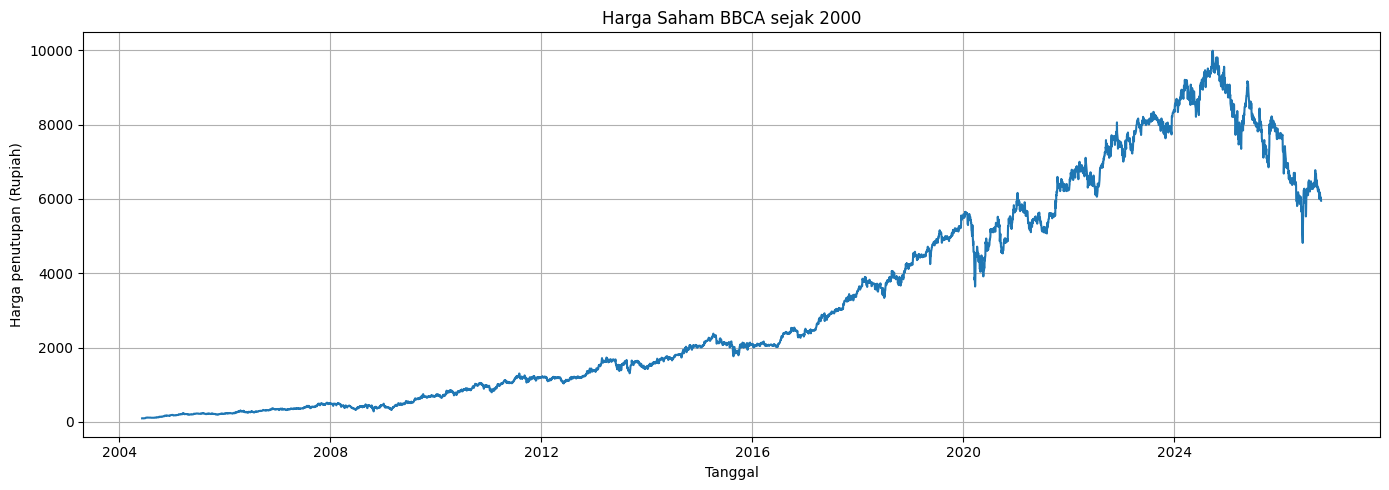


Statistik deskriptif:
count    5507.000000
mean     3182.850317
std      2835.448734
min        94.219902
25%       689.329926
50%      2063.480713
75%      5436.686035
max      9989.796875
Name: BBCA, dtype: float64


In [ ]:

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# 1. Mengunduh data historis BBCA sejak IPO
df = yf.download(
    "BBCA.JK",
    start="2000-05-31",
    auto_adjust=False,
    progress=False
)

# 2. Mengatasi format kolom MultiIndex dari yfinance
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 3. Memeriksa ketersediaan data
print("Jumlah observasi:", len(df))
print("Data paling awal:", df.index.min())
print("Data paling baru:", df.index.max())
print("\nLima data pertama:")
print(df.head())

print("\nInformasi data:")
print(df.info())

print("\nJumlah missing value:")
print(df.isnull().sum())

# 4. Memilih harga penutupan yang sudah disesuaikan
# Jika Adj Close tidak tersedia, gunakan Close
kolom_harga = "Adj Close" if "Adj Close" in df.columns else "Close"
harga = df[kolom_harga].dropna().astype(float)
harga.name = "BBCA"

# 5. Plot harga saham
plt.figure(figsize=(14, 5))
plt.plot(harga)
plt.title("Harga Saham BBCA sejak 2000")
plt.xlabel("Tanggal")
plt.ylabel("Harga penutupan (Rupiah)")
plt.grid(True)
plt.tight_layout()
plt.show()

# 6. Statistik deskriptif
print("\nStatistik deskriptif:")
print(harga.describe())


Indikasi Kuat Tidak Stasioner dalam Rata-rata (Mean)
- Tren harga naik sangat dominan secara jangka panjang dari 2004 hingga puncaknya mendekati 2024–2025.
- Karena rata-rata data terus berubah terhadap waktu ($E[Y_t] \neq \text{konstan}$), data ini jelas tidak stasioner dalam rata-rata. Implikasinya, pemodelan ARIMA/SARIMA wajib menggunakan differencing non-musiman ($d \ge 1$) nanti.

Indikasi Tidak Stasioner dalam Variansi (Heteroskedastisitas)
- Coba perhatikan lebar ayunan fluktuasi harga. Pada rentang tahun 2004–2012, fluktuasi harganya relatif kecil dalam nominal Rupiah. Namun saat harga berada di level tinggi (2022–2026 di atas 7.000), lebar gejolak harganya menjadi sangat besar.
- Fenomena di mana variansi membesar seiring meningkatnya level harga menandakan variansi data tidak konstan ($Var(Y_t) \neq \text{konstan}$). Untuk model linier seperti ARIMA/SARIMA, data seperti ini biasanya perlu ditransformasi lebih dahulu (misalnya transformasi Log $\ln(Y_t)$) agar variansinya stabil sebelum dihitung differencing.

Kemiringan Distribusi (Skewness)
- Nilai Rata-rata (3.181,84) jauh berada di atas Median (2.062,56). Ditambah lagi nilai Standar Deviasi (2.835,47) hampir seukuran dengan rata-ratanya. Ini mengindikasikan distribusi harga saham BBCA miring ke kanan (positive/right skewness), khas data finansial yang tumbuh secara eksponensial dalam jangka panjang.

Syok Eksternal & Pola Tren
- Terlihat adanya penurunan mendadak (structural break) pada awal 2020 akibat syok pandemi COVID-19, serta tren koreksi yang cukup signifikan pada periode 2024–2026.

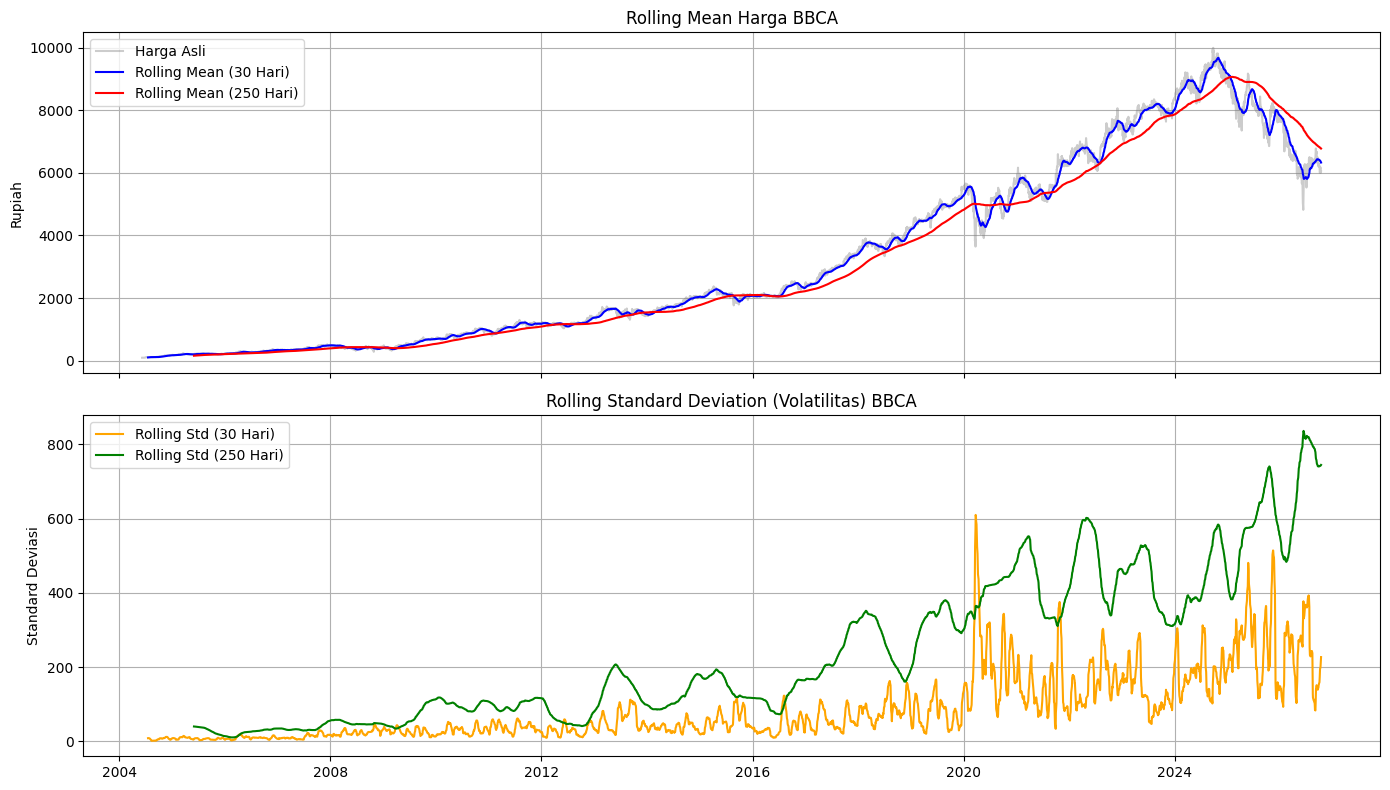

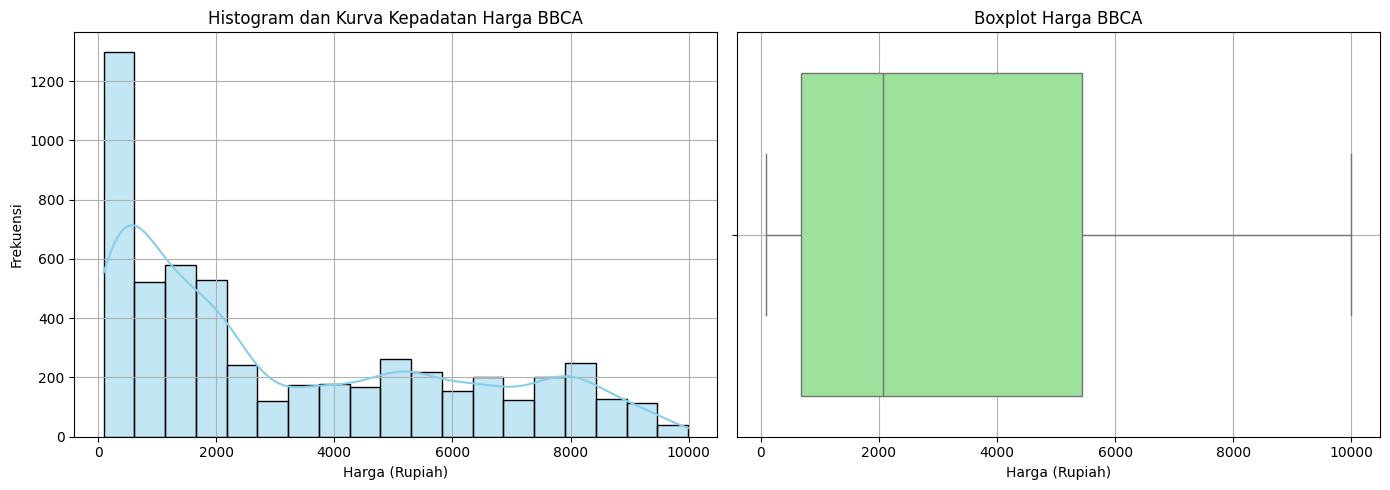

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Handling missing value dengan forward fill
harga_clean = harga.ffill()

# 2. Perhitungan Rolling Mean dan Rolling Standard Deviation
window_pendek = 30  # ~1 bulan hari kerja
window_panjang = 250  # ~1 tahun hari kerja

rolling_mean_30 = harga_clean.rolling(window=window_pendek).mean()
rolling_std_30 = harga_clean.rolling(window=window_pendek).std()

rolling_mean_250 = harga_clean.rolling(window=window_panjang).mean()
rolling_std_250 = harga_clean.rolling(window=window_panjang).std()

# 3. Plot Rolling Statistics
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Plot Rolling Mean
axes[0].plot(harga_clean, label="Harga Asli", color="gray", alpha=0.4)
axes[0].plot(
    rolling_mean_30, label=f"Rolling Mean ({window_pendek} Hari)", color="blue"
)
axes[0].plot(
    rolling_mean_250, label=f"Rolling Mean ({window_panjang} Hari)", color="red"
)
axes[0].set_title("Rolling Mean Harga BBCA")
axes[0].set_ylabel("Rupiah")
axes[0].legend()
axes[0].grid(True)

# Plot Rolling Standard Deviation (Volatilitas)
axes[1].plot(
    rolling_std_30,
    label=f"Rolling Std ({window_pendek} Hari)",
    color="orange",
)
axes[1].plot(
    rolling_std_250,
    label=f"Rolling Std ({window_panjang} Hari)",
    color="green",
)
axes[1].set_title("Rolling Standard Deviation (Volatilitas) BBCA")
axes[1].set_ylabel("Standard Deviasi")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# 4. Plot Histogram dan Boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram + KDE
sns.histplot(harga_clean, kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Histogram dan Kurva Kepadatan Harga BBCA")
axes[0].set_xlabel("Harga (Rupiah)")
axes[0].set_ylabel("Frekuensi")
axes[0].grid(True)

# Boxplot
sns.boxplot(x=harga_clean, ax=axes[1], color="lightgreen")
axes[1].set_title("Boxplot Harga BBCA")
axes[1].set_xlabel("Harga (Rupiah)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

Rolling Mean (Tren Non-Stasioner)
-
- Rolling Mean (baik 30 maupun 250 hari) terus bergerak naik secara sistematis dan tidak pernah kembali ke nilai rata-rata jalannya.
- Indikasi: Data tidak stasioner dalam rata-rata.
- Implikasi Model: Kita perlu melakukan differencing non-musiman minimal 1 kali ($d=1$) setelah data ditransformasi log.


Rolling Standard Deviation (Volatilitas Membesar)
-
- Grafik Rolling Std memperlihatkan nilai standar deviasi yang terus melonjak seiring berjalannya waktu, dari di bawah 50 (pada periode 2004–2012) naik drastis hingga menyentuh angka 600–800+ (periode 2020–2026).
- Indikasi: Terjadi heteroskedastisitas (variansi tidak konstan). Saat harga saham BBCA masih di level ratusan Rupiah, naik-turun 50 Perak itu persentase yang besar. Tapi saat harganya sudah di angka 8.000–9.000, fluktuasi harian bisa mencapai ratusan Rupiah.
- Implikasi Model: Model linier seperti ARIMA/SARIMA mengasumsikan variansi sisaan (residual) yang konstan. Karena variansi data aslinya membesar (funnel shape), kita wajib melakukan transformasi Log ($\ln(Y_t)$) terlebih dahulu sebelum melakukan differencing. Transformasi log akan menstabilkan variansi sehingga skalanya proporsional.


Histogram dan Kurva Kepadatan (KDE)
-
- Bentuk distribusinya sangat miring ke kanan (positive/right skewness) dengan puncak tertinggi menumpuk di harga murah (< 2.000). Ada juga beberapa benjolan kecil (multimodal) di rentang harga 5.000 dan 8.000.
- Indikasi: Data tidak berdistribusi normal, melainkan mengikuti pola pertumbuhan eksponensial (compounding effect khas aset finansial). Ini makin memperkuat alasan kenapa transformasi Log sangat dibutuhkan.


Boxplot
-
- Kotak Interquartile Range (IQR) melebar ke kanan dan garis median terdorong ke kiri.
- Indikasi Menarik: Perhatikan bahwa tidak ada titik-titik melayang (outlier) di sebelah kanan whisker. Ini menunjukkan bahwa lonjakan harga hingga 10.000 Rupiah bukanlah anomali data/kesalahan input, melainkan tren pergerakan harga wajar yang berkesinambungan.

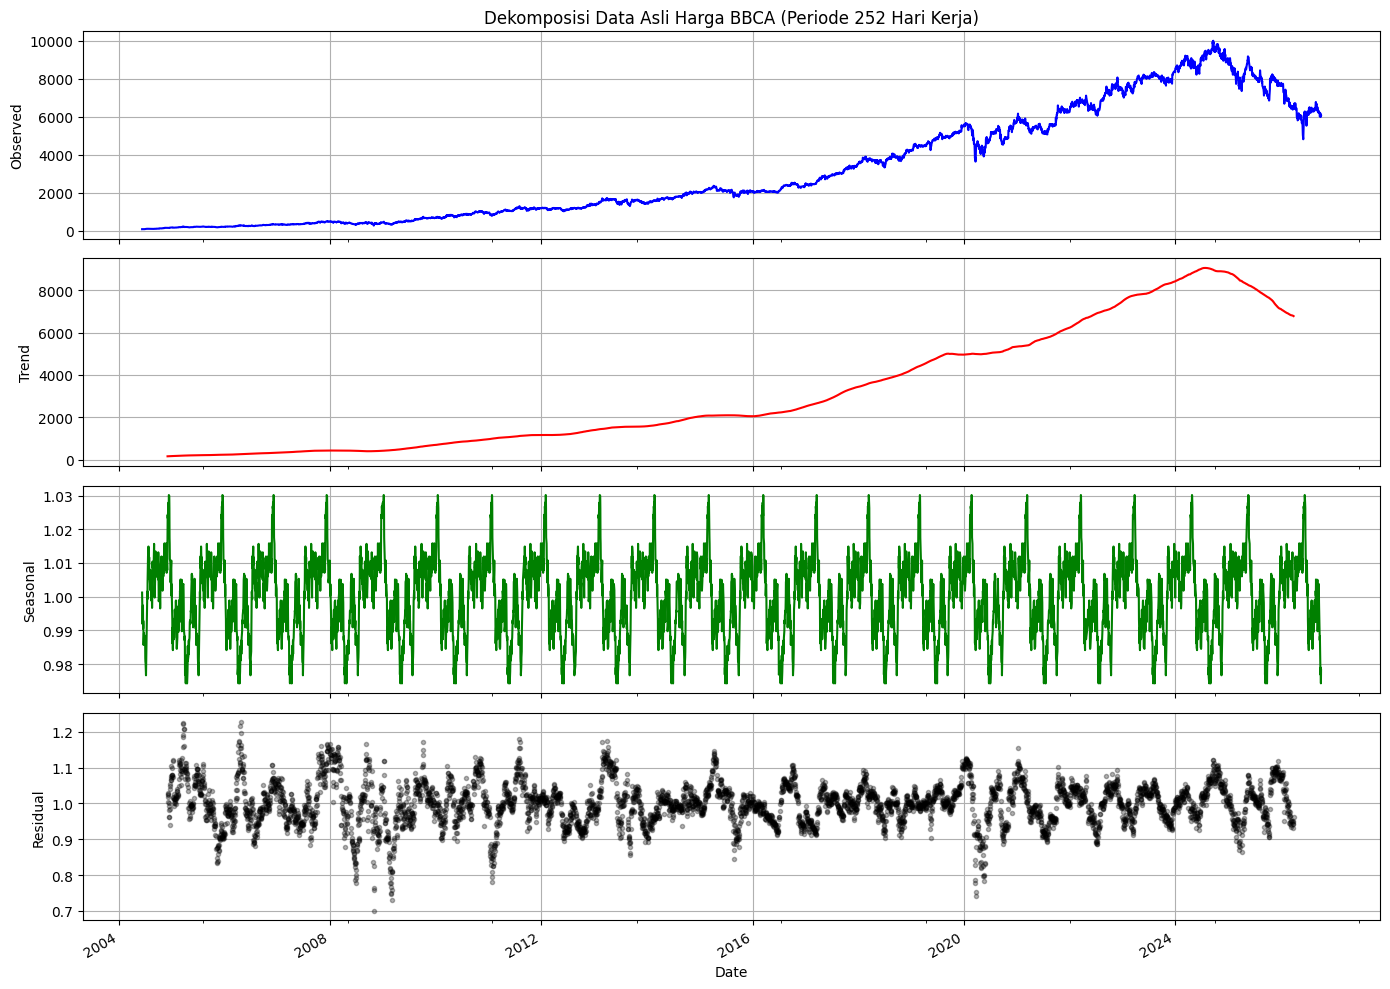

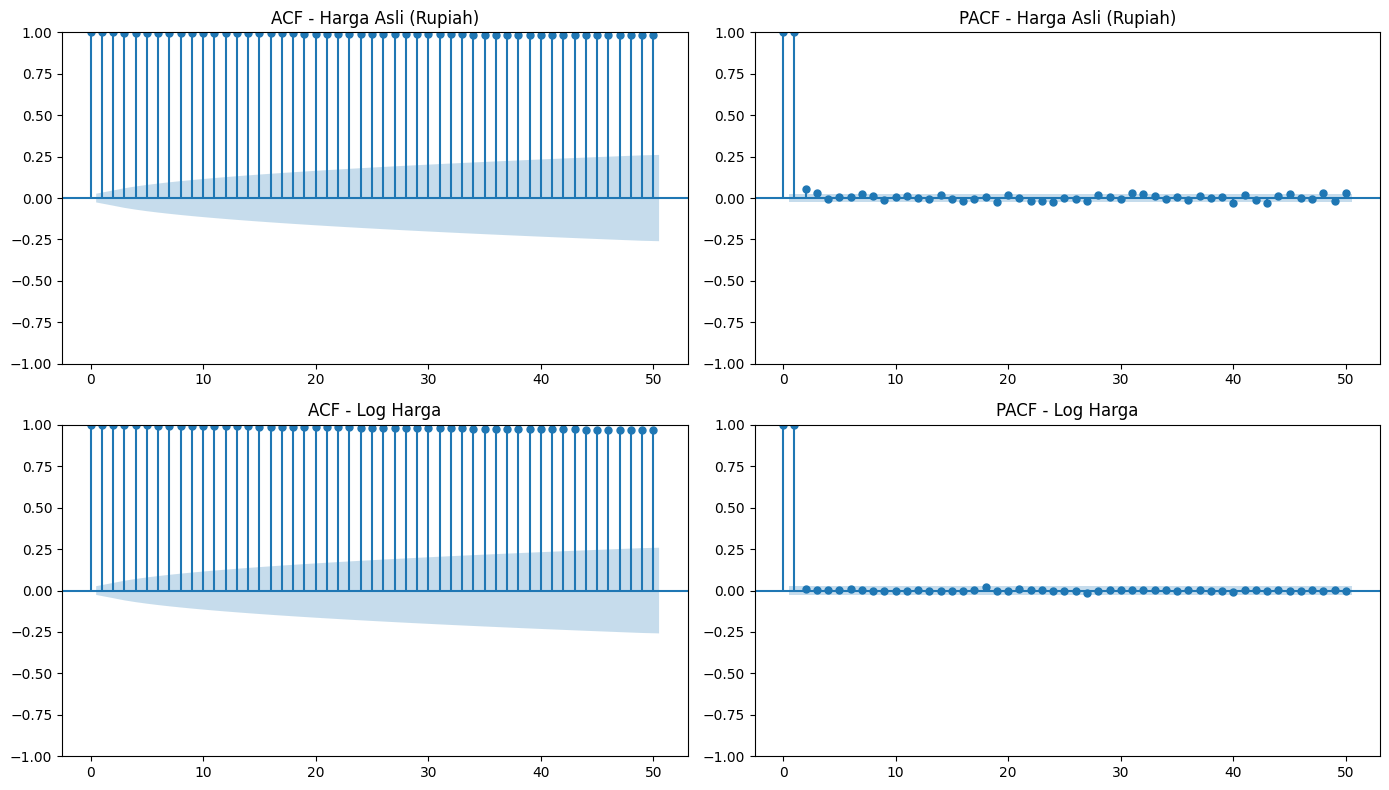

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. Dekomposisi Data Asli (Level Rupiah)
# Period=252 mewakili jumlah hari kerja bursa dalam 1 tahun
decomp = seasonal_decompose(harga_clean, model='multiplicative', period=252)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
decomp.observed.plot(ax=axes[0], color='blue')
axes[0].set_ylabel('Observed')
axes[0].set_title('Dekomposisi Data Asli Harga BBCA (Periode 252 Hari Kerja)')
axes[0].grid(True)

decomp.trend.plot(ax=axes[1], color='red')
axes[1].set_ylabel('Trend')
axes[1].grid(True)

decomp.seasonal.plot(ax=axes[2], color='green')
axes[2].set_ylabel('Seasonal')
axes[2].grid(True)

decomp.resid.plot(ax=axes[3], color='black', marker='.', linestyle='None', alpha=0.3)
axes[3].set_ylabel('Residual')
axes[3].grid(True)

plt.tight_layout()
plt.show()

# 2. Plot ACF dan PACF Data Asli vs Log Harga (Semua dalam level asli / tanpa differencing)
log_harga = np.log(harga_clean)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Data Asli (Rupiah)
plot_acf(harga_clean, ax=axes[0, 0], lags=50, title="ACF - Harga Asli (Rupiah)")
plot_pacf(harga_clean, ax=axes[0, 1], lags=50, title="PACF - Harga Asli (Rupiah)")

# Data Log Harga
plot_acf(log_harga, ax=axes[1, 0], lags=50, title="ACF - Log Harga")
plot_pacf(log_harga, ax=axes[1, 1], lags=50, title="PACF - Log Harga")

plt.tight_layout()
plt.show()

Plot ACF/PACF skala Log kita sertakan untuk memastikan apakah transformasi log mengubah struktur autokorelasi data asli atau tidak. Hasilnya menunjukkan bahwa transformasi log menstabilkan variansi, namun struktur non-stasioner pada rata-rata tetap bertahan.

Interpretasi Dekomposisi Data (Periode 252 Hari Kerja)
-
- Observed: Menampilkan pergerakan harga asli BBCA dari 2004 sampai 2026 yang didominasi oleh tren jangka panjang.
- Trend: Komponen tren berhasil diekstrak dengan mulus. Terlihat kenaikan konsisten hingga mencapai puncaknya di area 2024–2025 sebelum mengalami fase koreksi.
- Seasonal: Nilai komponen musiman bergerak sangat tipis di rentang $0{,}98$ hingga $1{,}03$ ($\pm 2-3\%$). Variasi yang sangat kecil ini mengindikasikan bahwa pola musiman tahunan pada harga level asli tidak dominan.
- Residual: Sebaran sisaan (random noise) masih memiliki lebar gejolak yang tidak seragam (volatilitas tinggi di awal periode 2004–2008 dan saat COVID-19 2020). Ini memperkuat alasan mengapa transformasi Log dan differencing perlu dilakukan.

Plot ACF (Harga Asli & Log Harga):
-
- Pola: Batang ACF meluruh sangat lambat (extemely slow decay) dan nilainya bertahan mendekati $1{,}0$ hingga lag 50.
- Indikasi: Ciri khas utama bahwa data sangat tidak stasioner dalam rata-rata. Data menganut proses Random Walk / Memiliki Unit Root, sehingga pemodelan wajib menggunakan differencing non-musiman ($d=1$)

Plot PACF (Harga Asli & Log Harga):
-
- Pola: Terjadi cut-off mendadak. Hanya lag 1 yang signifikan (mendekati $1{,}0$), sedangkan lag 2 dan seterusnya langsung jatuh ke area nol (di dalam batas signifikansi).
- Indikasi: Mengonfirmasi struktur $AR(1)$ pada level data, di mana harga hari ini $Y_t$ sangat didominasi oleh harga kemarin $Y_{t-1}$.

=== RINGKASAN PEMISAHAN DATA ===
Skenario 1 -> Training: 4610 obs (2004-06-08 s/d 2022-12-30) | Testing: 895 obs
Skenario 2 -> Training: 5086 obs (2004-06-08 s/d 2024-12-30) | Testing: 419 obs



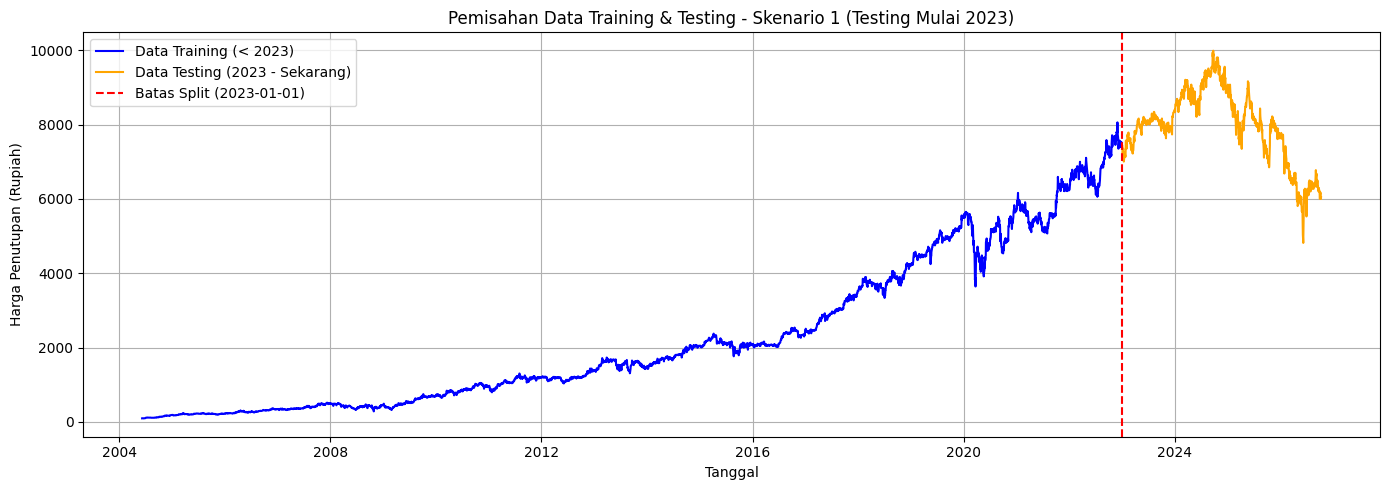

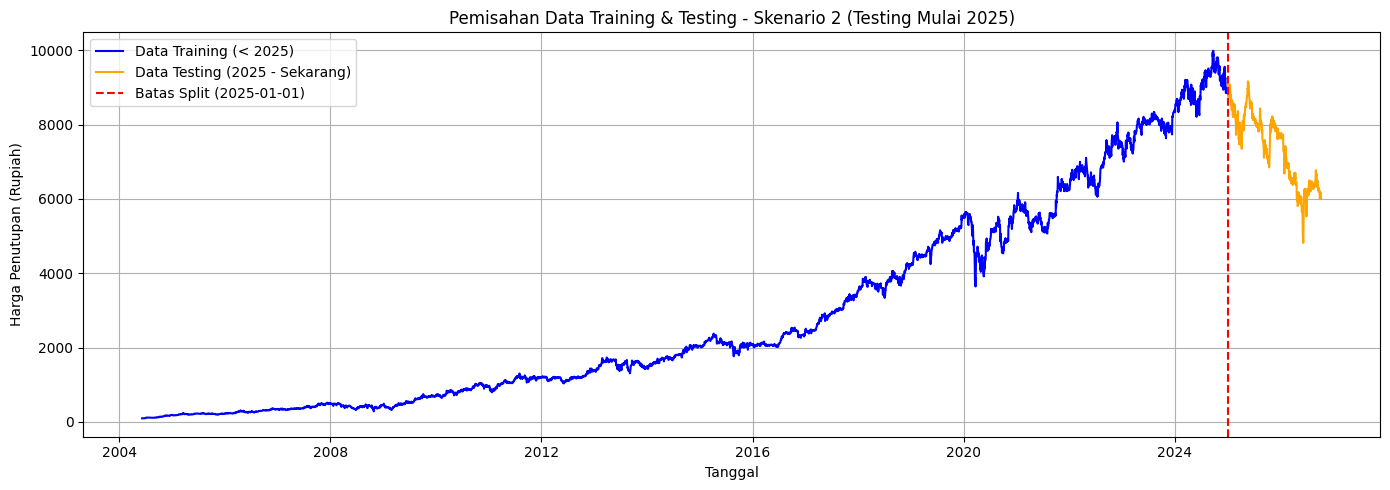

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

# Ensure harga_clean from previous step is ready
harga_clean = df["Adj Close"].dropna().ffill().astype(float)
harga_clean.name = "BBCA"

# ==============================================================================
# 1. SPLIT DATA TRAINING & TESTING
# ==============================================================================

# 1. Pemisahan Data

# Skenario 1: Test mulai 2023-01-01
train_sk1 = harga_clean[harga_clean.index < "2023-01-01"]
test_sk1 = harga_clean[harga_clean.index >= "2023-01-01"]

# Skenario 2: Test mulai 2025-01-01
train_sk2 = harga_clean[harga_clean.index < "2025-01-01"]
test_sk2 = harga_clean[harga_clean.index >= "2025-01-01"]

print("=== RINGKASAN PEMISAHAN DATA ===")
print(f"Skenario 1 -> Training: {len(train_sk1)} obs ({train_sk1.index.min().date()} s/d {train_sk1.index.max().date()}) | Testing: {len(test_sk1)} obs")
print(f"Skenario 2 -> Training: {len(train_sk2)} obs ({train_sk2.index.min().date()} s/d {train_sk2.index.max().date()}) | Testing: {len(test_sk2)} obs\n")

# 2. Plot Skenario 1 (Testing Mulai 2023)
plt.figure(figsize=(14, 5))
plt.plot(
    train_sk1.index, train_sk1, label="Data Training (< 2023)", color="blue"
)
plt.plot(
    test_sk1.index,
    test_sk1,
    label="Data Testing (2023 - Sekarang)",
    color="orange",
)
plt.axvline(
    pd.Timestamp("2023-01-01"),
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Batas Split (2023-01-01)",
)
plt.title(
    "Pemisahan Data Training & Testing - Skenario 1 (Testing Mulai 2023)"
)
plt.xlabel("Tanggal")
plt.ylabel("Harga Penutupan (Rupiah)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Plot Skenario 2 (Testing Mulai 2025)
plt.figure(figsize=(14, 5))
plt.plot(
    train_sk2.index, train_sk2, label="Data Training (< 2025)", color="blue"
)
plt.plot(
    test_sk2.index,
    test_sk2,
    label="Data Testing (2025 - Sekarang)",
    color="orange",
)
plt.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Batas Split (2025-01-01)",
)
plt.title(
    "Pemisahan Data Training & Testing - Skenario 2 (Testing Mulai 2025)"
)
plt.xlabel("Tanggal")
plt.ylabel("Harga Penutupan (Rupiah)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Skenario 1 (Testing Mulai 2023 - Horizon Panjang)
-
- Karakteristik Data Training (< 2023): Data training didominasi oleh tren naik (bullish trend) yang sangat kuat dan stabil selama kurang lebih 18,5 tahun, meskipun sempat terpukul syok sementara saat COVID-19 di 2020.
- Karakteristik Data Testing (2023 – 2026): Data testing memuat dua fase pasar yang bertolak belakang: fase kenaikan lanjutan hingga mencapai puncak All-Time High (~10.000 di akhir 2024), dilanjutkan dengan fase koreksi/penurunan (bearish) yang cukup tajam hingga 2026.

Tantangan Model:
- Regime Shift (Perubahan Rezim Tren): Karena data training nyaris tidak pernah mengalami pembalikan tren turun jangka panjang, parameter model (khususnya nilai drift / konstanta tren) yang dipelajari dari data train akan sangat cenderung mengasumsikan bahwa harga saham akan selalu naik dalam jangka panjang.
- Stress Test untuk ARIMA/SARIMA: Skenario 1 ini akan menjadi ujian yang sangat berat (stress test) bagi model linier, karena kita menguji apakah model yang dibentuk dari tren naik mampu merespons pembalikan arah pasar di periode 2025–2026.

Skenario 2 (Testing Mulai 2025 - Horizon Pendek)
-
- Karakteristik Data Training (< 2025): Data training sudah mencakup keseluruhan perjalanan tren naik BBCA hingga mencapai titik puncaknya (~10.000 di akhir 2024) serta pembentukan pola puncak (toping phase).
- Karakteristik Data Testing (2025 – 2026): Data testing murni berisi fase koreksi/penurunan harga yang sedang terjadi saat ini.

Keunggulan:
- Kecukupan Informasi Puncak: Model pada Skenario 2 sudah "melihat" level harga tertinggi 10.000 di data training-nya, sehingga estimasi variansi dan tingkat volatilitas di area harga tinggi sudah terekam penuh sebelum peramalan dilakukan.
- Evaluasi Adaptasi Tren: Skenario ini fokus menguji seberapa sensitif model ARIMA/SARIMA dalam menangkap momentum penurunan harga tanpa terdistorsi oleh tren historis 20 tahun sebelumnya.

Perbandingan kedua skenario ini bagus banget. Skenario 1 menguji daya tahan peramalan jangka panjang (3,8 tahun), sedangkan Skenario 2 menguji ketepatan peramalan jangka menengah (1,8 tahun) pada kondisi pasar yang sedang terkoreksi.

=== STATISTIK DESKRIPTIF DATA TRAINING ===
       Train Skenario 1 (< 2023)  Train Skenario 2 (< 2025)
count                4610.000000                5086.000000
mean                 2257.505902                2838.865297
std                  2037.801694                2661.319252
min                    94.219917                  94.219917
25%                   473.268127                 530.522583
50%                  1588.905151                1860.607117
75%                  3723.267273                4803.481201
max                  8060.771973                9989.796875


Menampilkan visualisasi untuk Training Skenario 1 (< 2023)...


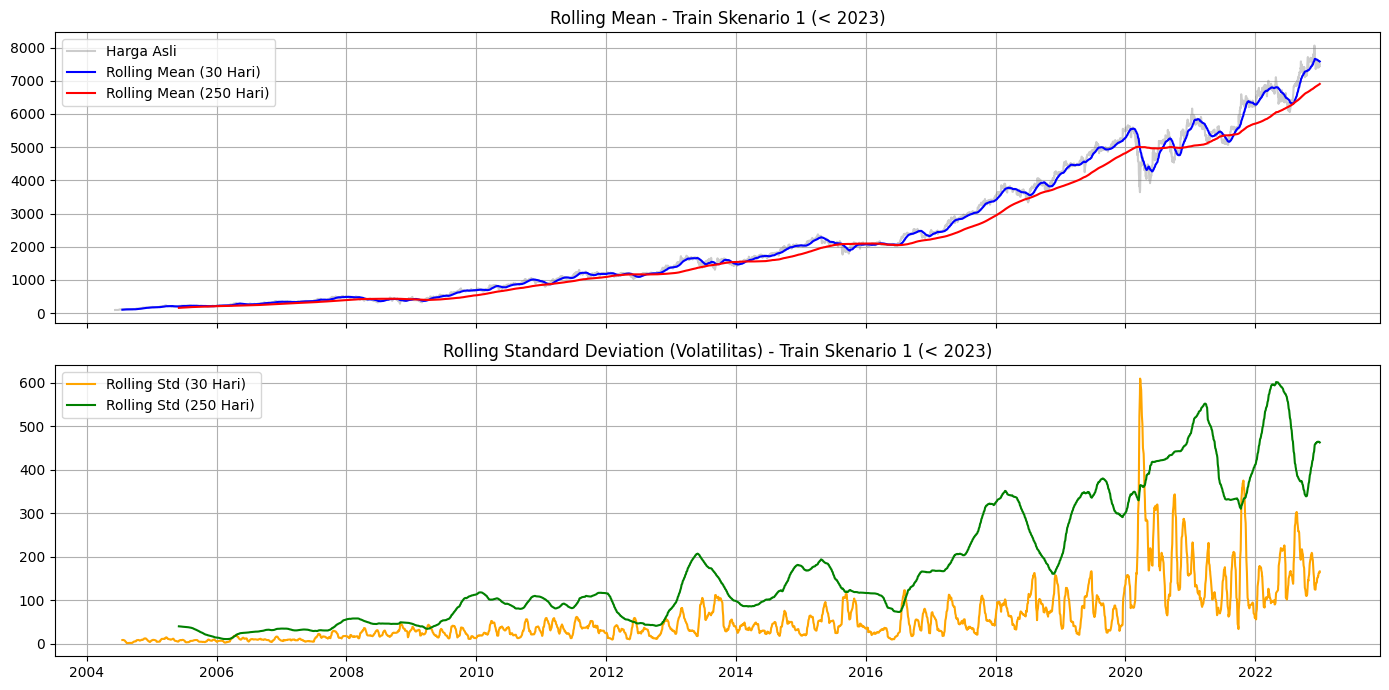

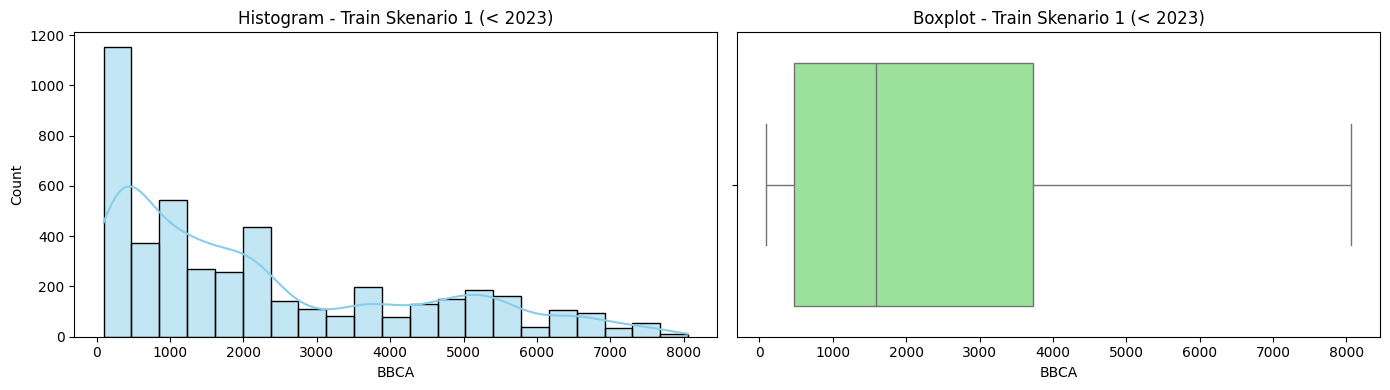

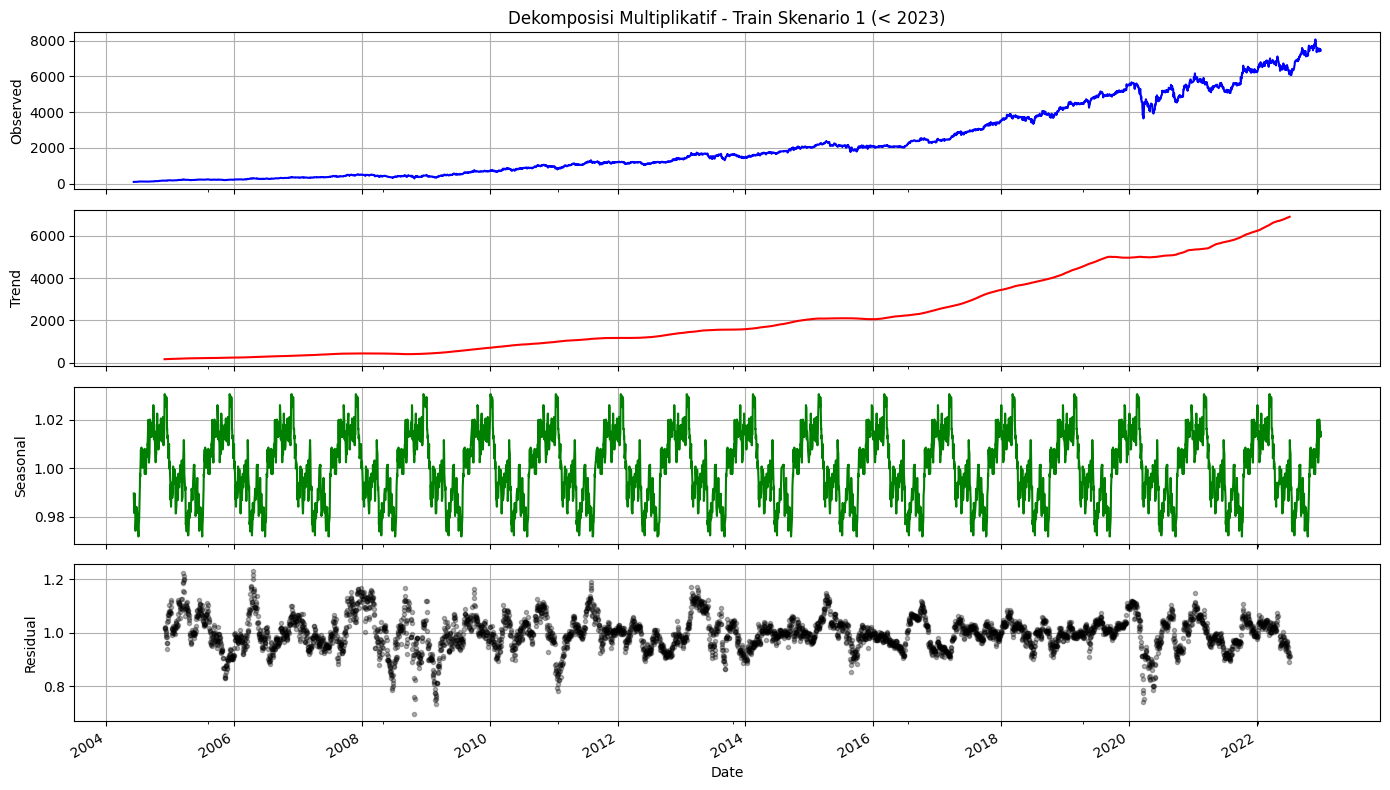

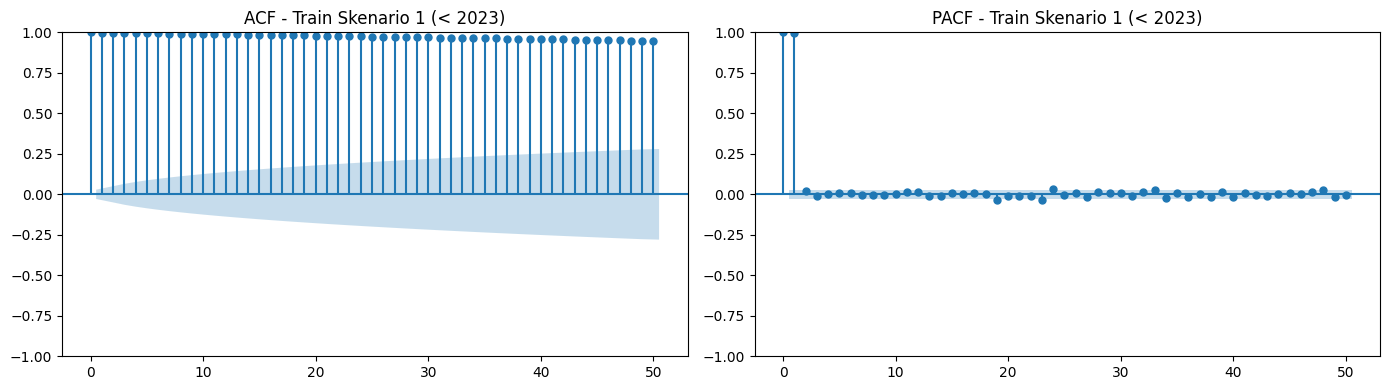

Menampilkan visualisasi untuk Training Skenario 2 (< 2025)...


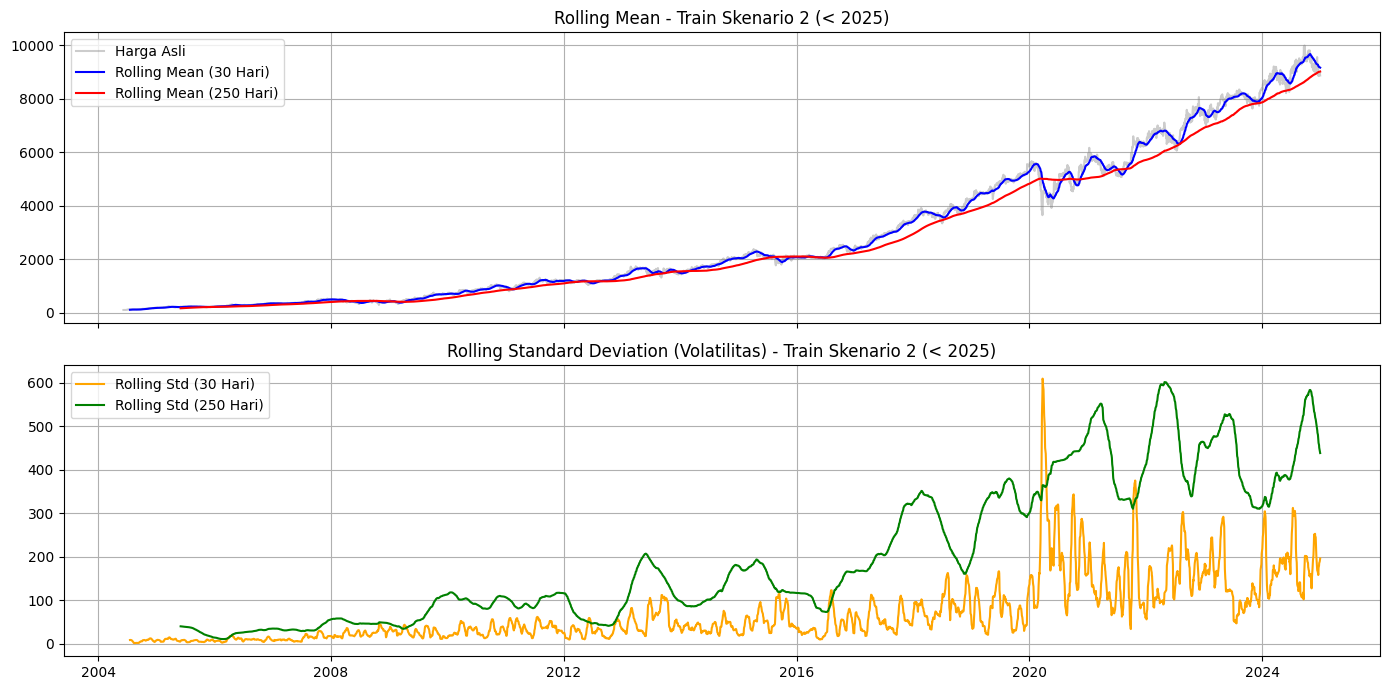

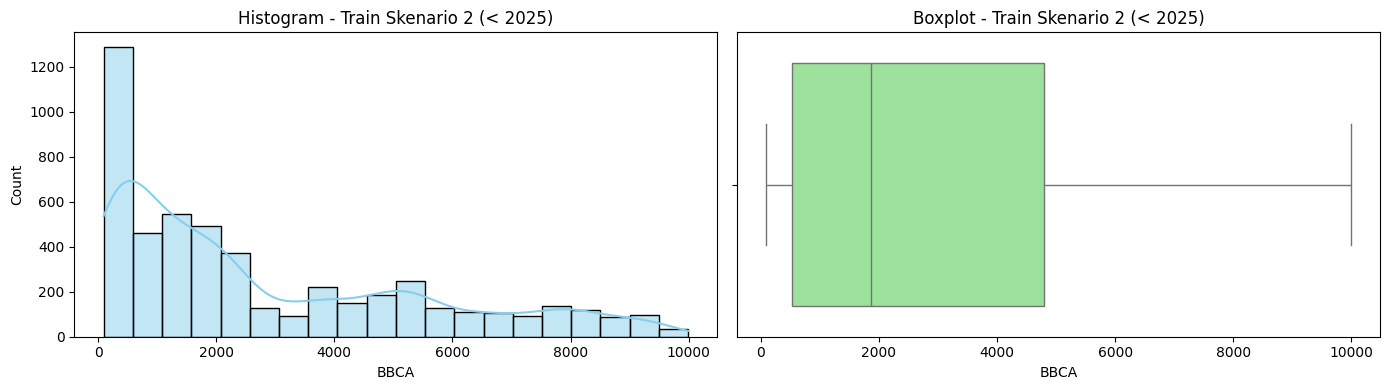

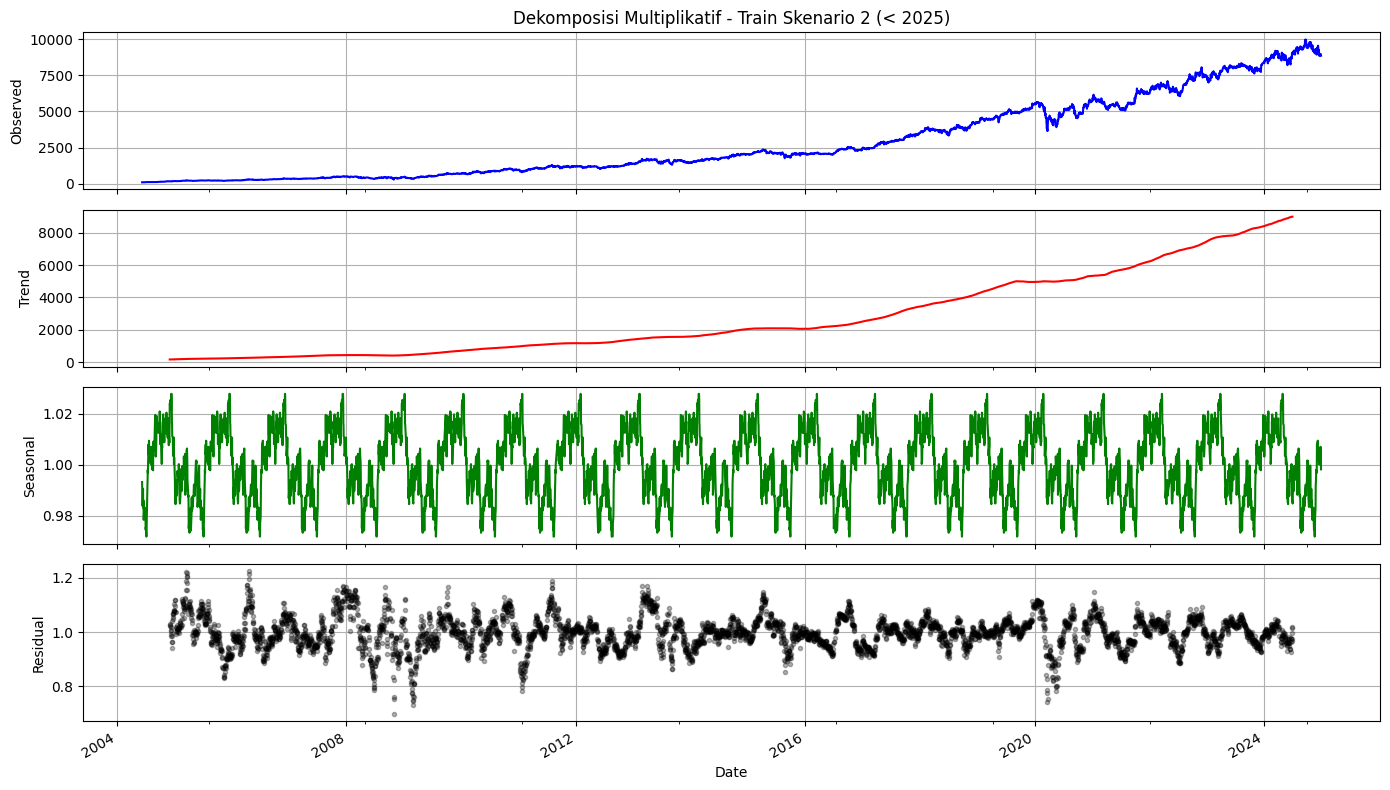

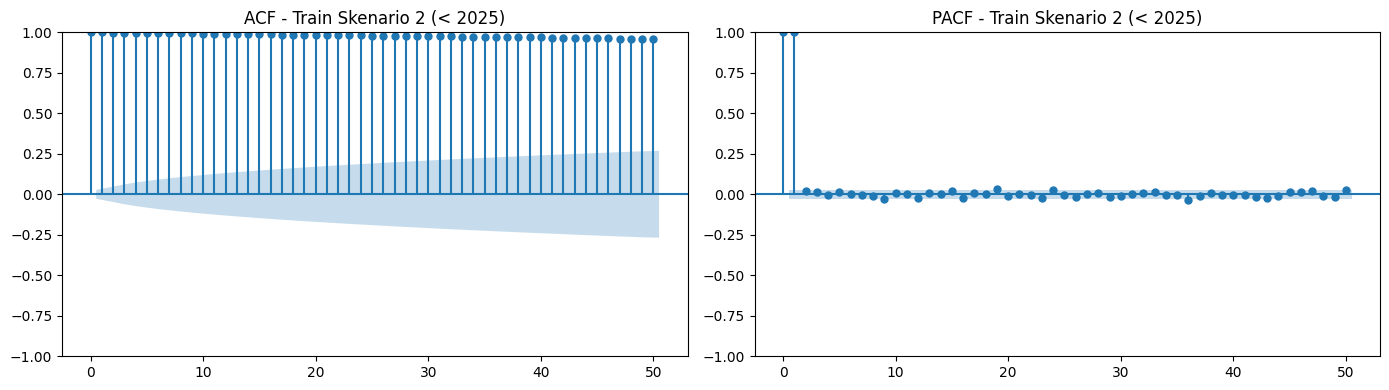

In [ ]:
# ==============================================================================
# 2. STATISTIK DESKRIPTIF DATA TRAINING
# ==============================================================================
df_stat = pd.DataFrame({
    'Train Skenario 1 (< 2023)': train_sk1.describe(),
    'Train Skenario 2 (< 2025)': train_sk2.describe()
})
print("=== STATISTIK DESKRIPTIF DATA TRAINING ===")
print(df_stat)
print("\n")

# ==============================================================================
# FUNGSI EKSPLORASI VISUAL DATA TRAINING
# ==============================================================================
def visualisasi_eksplorasi(series, nama_skenario):
    # a. Plot Tren & Rolling Statistics
    fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    roll_mean_30 = series.rolling(30).mean()
    roll_mean_250 = series.rolling(250).mean()
    roll_std_30 = series.rolling(30).std()
    roll_std_250 = series.rolling(250).std()

    axes[0].plot(series, color='gray', alpha=0.4, label='Harga Asli')
    axes[0].plot(roll_mean_30, color='blue', label='Rolling Mean (30 Hari)')
    axes[0].plot(roll_mean_250, color='red', label='Rolling Mean (250 Hari)')
    axes[0].set_title(f'Rolling Mean - {nama_skenario}')
    axes[0].grid(True); axes[0].legend()

    axes[1].plot(roll_std_30, color='orange', label='Rolling Std (30 Hari)')
    axes[1].plot(roll_std_250, color='green', label='Rolling Std (250 Hari)')
    axes[1].set_title(f'Rolling Standard Deviation (Volatilitas) - {nama_skenario}')
    axes[1].grid(True); axes[1].legend()
    plt.tight_layout(); plt.show()

    # b. Histogram & Boxplot
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.histplot(series, kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Histogram - {nama_skenario}')
    sns.boxplot(x=series, ax=axes[1], color='lightgreen')
    axes[1].set_title(f'Boxplot - {nama_skenario}')
    plt.tight_layout(); plt.show()

    # c. Plot Dekomposisi Multiplikatif (252 hari kerja)
    decomp = seasonal_decompose(series, model='multiplicative', period=252)
    fig, axes = plt.subplots(4, 1, figsize=(14, 8), sharex=True)
    decomp.observed.plot(ax=axes[0], color='blue'); axes[0].set_ylabel('Observed')
    axes[0].set_title(f'Dekomposisi Multiplikatif - {nama_skenario}')
    decomp.trend.plot(ax=axes[1], color='red'); axes[1].set_ylabel('Trend')
    decomp.seasonal.plot(ax=axes[2], color='green'); axes[2].set_ylabel('Seasonal')
    decomp.resid.plot(ax=axes[3], color='black', marker='.', linestyle='None', alpha=0.3); axes[3].set_ylabel('Residual')
    for ax in axes: ax.grid(True)
    plt.tight_layout(); plt.show()

    # d. Plot ACF dan PACF
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(series, ax=axes[0], lags=50, title=f'ACF - {nama_skenario}')
    plot_pacf(series, ax=axes[1], lags=50, title=f'PACF - {nama_skenario}')
    plt.tight_layout(); plt.show()

# Run Visualisasi untuk Training Skenario 1 dan 2
print("Menampilkan visualisasi untuk Training Skenario 1 (< 2023)...")
visualisasi_eksplorasi(train_sk1, "Train Skenario 1 (< 2023)")

print("Menampilkan visualisasi untuk Training Skenario 2 (< 2025)...")
visualisasi_eksplorasi(train_sk2, "Train Skenario 2 (< 2025)")

Skenario 1
-
Statistik Deskriptif
- Miring ke Kanan (Right-Skewed): Nilai rata-rata (2.257,51) jauh melampaui median (1.588,91). Hal ini terjadi karena sebagian besar masa perdagangan saham BBCA selama 2004–2022 berada di area harga bawah.
- Rentang Pertumbuhan Lebar: Rentang harga membentang sangat jauh dari titik terendah 94,22 hingga puncak 8.060,77. Standar deviasi yang tinggi (2.037,80) mencerminkan efek akumulasi pertumbuhan (compounding growth) selama 18,5 tahun.

Plot
- Rolling Mean: Garis rata-rata bergerak (baik 30 maupun 250 hari) terus menanjak dan tidak pernah stabil di satu nilai tengah. Ini merupakan sinyal awal bahwa data tidak stasioner dalam rata-rata.
- Rolling Std: Volatilitas bergerak dalam rentang 2004–2012 berada di tingkat yang sangat rendah (di bawah 50). Namun, seiring tingginya harga saham, volatilitas melonjak drastis hingga menyentuh angka 600 saat syok COVID-19 di 2020 dan tetap berada di level tinggi. Ini mengonfirmasi adanya masalah heteroskedastisitas (variansi tidak konstan).
- Histogram: Penumpukan frekuensi paling padat berada pada skala harga di bawah 2.000.
- Boxplot: Garis median terdorong ke kiri dengan Interquartile Range (IQR) yang melebar ke kanan. Tidak ditemukan adanya pencilan (outlier), yang menegaskan bahwa tren kenaikan harga saham hingga melampaui level 8.000 terbentuk secara wajar dan berkelanjutan.

Dekomposisi Multiplikatif (Periode 252 Hari Kerja)
- Trend: Komponen tren mendominasi keseluruhan pergerakan harga asli.
- Seasonal: Variasi komponen musiman bergerak sangat sempit pada selang 0,97 hingga 1,03 ($\pm 3\%$). Ini mengindikasikan bahwa pola musiman tahunan pada skala harian asli tergolong sangat lemah.
- Residual: Sisaan menunjukkan fenomena pengelompokan volatilitas (volatility clustering), di mana gejolak besar cenderung berkumpul pada periode krisis (seperti 2008 dan 2020).

Plot ACF dan PACF
- ACF: Nilai autokorelasi meluruh sangat lambat (extemely slow decay) dan bertahan mendatar mendekati angka 1,0 hingga lag 50. Ini merupakan bukti khas bahwa data sangat tidak stasioner dan mengandung unit root.
- PACF: Terjadi cut-off mendadak setelah lag 1. Pola ini menandakan bahwa harga hari ini sangat dipengaruhi oleh harga 1 hari sebelumnya ($AR(1)$ / Random Walk).

Skenario 2
-

Statistik Deskriptif
- Kemiringan Distribusi (Right-Skewed): Nilai rata-rata (2.838,87) berada signifikan di atas median (1.860,61). Hal ini menandakan penumpukan histori harga saham masih dominan di area level rendah hingga menengah.
- Standar Deviasi Lebih Tinggi: Standar deviasi meningkat menjadi 2.661,32 (dibandingkan 2.037,80 pada Skenario 1). Peningkatan ini dipicu oleh masuknya data reli harga tahun 2023–2024 yang berhasil menyentuh harga tertinggi mendekati level 10.000 (9.989,80).

Plot
- Rolling Mean: Tren rata-rata bergerak (30 dan 250 hari) terus menanjak tajam hingga akhir 2024 tanpa pernah kembali ke titik rata-rata historisnya. Ini mengonfirmasi bahwa data sangat tidak stasioner dalam rata-rata.
- Rolling Std: Volatilitas bergerak (khususnya rolling std 250 hari) terus bertahan di level yang sangat tinggi (300 hingga di atas 600) sepanjang periode 2020–2024. Hal ini makin mempertegas masalah heteroskedastisitas (variansi tidak konstan) pada data level.
- Histogram: Distribusi harga miring ke kanan dengan frekuensi tertinggi menumpuk di bawah 2.000. Namun, terdapat benjolan frekuensi (secondary mode) yang lebih lebar di kisaran 4.000–8.000 akibat reli panjang periode 2021–2024.
- Boxplot: Rentang antar-kuartil (IQR) meluas drastis ke kanan mendekati level 5.000. Sama seperti Skenario 1, tidak terdapat pencilan (outlier) di ujung kanan whisker, yang menandakan kenaikan harga hingga mendekati 10.000 adalah tren pertumbuhan murni.

Dekomposisi Multiplikatif (Periode 252 Hari Kerja)
- Trend: Komponen tren memperlihatkan pendakian yang sangat dominan hingga puncaknya di akhir 2024.
- Seasonal: Variasi musiman bergerak sangat sempit pada rentang 0,97 hingga 1,03 ($\pm 3\%$). Ini mengindikasikan pola musiman tahunan pada data harian level asli hampir tidak memberikan kontribusi signifikan.
- Residual: Sisaan menunjukkan pengelompokan volatilitas (volatility clustering) yang lebar pada krisis 2008, syok COVID-19 2020, serta dinamika pasar di rentang 2022–2024.

Plot ACF dan PACF
- ACF: Batang autokorelasi meluruh sangat lambat (extremely slow decay) dan bertahan mendatar mendekati nilai 1,0 hingga lag 50. Ini adalah bukti statistik utama adanya sifat non-stationary / unit root.
- PACF: Terjadi cut-off tajam secara mendadak tepat setelah lag 1. Struktur ini mengonfirmasi karakteristik proses Random Walk / $AR(1)$ pada data level.

Kedua skenario terbukti sama-sama tidak stasioner baik dalam rata-rata maupun variansi.

In [ ]:

# ==============================================================================
# 3. UJI FORMAL STASIONERITAS & UJI BOX-COX (LAMBDA & CI 95%)
# ==============================================================================
def uji_formal_lengkap(series, nama_skenario):
    print(f"==================================================")
    print(f"UJI FORMAL & BOX-COX: {nama_skenario}")
    print(f"==================================================")

    # 1. ADF Test
    adf_res = adfuller(series)
    print(f"[1] Uji ADF:")
    print(f"    ADF Statistic : {adf_res[0]:.4f}")
    print(f"    p-value       : {adf_res[1]:.4f}")
    print(f"    Kesimpulan    : " + ("Stasioner" if adf_res[1] < 0.05 else "TIDAK Stasioner (Ada Unit Root)"))

    # 2. KPSS Test
    kpss_res = kpss(series, regression='c', nlags="auto")
    print(f"[2] Uji KPSS:")
    print(f"    KPSS Statistic: {kpss_res[0]:.4f}")
    print(f"    p-value       : {kpss_res[1]:.4f}")
    print(f"    Kesimpulan    : " + ("TIDAK Stasioner" if kpss_res[1] < 0.05 else "Stasioner"))

    # 3. Uji Box-Cox & Selang Kepercayaan 95%
    # Menghitung Profile Likelihood untuk menemukan interval 95% (Likelihood Ratio Test)
    fitted_data, lambda_opt = stats.boxcox(series)

    # Grid search lambda untuk mencari confidence interval 95%
    lambdas = np.linspace(lambda_opt - 1.0, lambda_opt + 1.0, 2000)
    loglik = [stats.boxcox_llf(lmb, series) for lmb in lambdas]
    max_loglik = stats.boxcox_llf(lambda_opt, series)

    # Batas ambang Chi-Square 1 d.f. pada alpha 0.05 (3.841 / 2 = 1.9207)
    threshold = max_loglik - 1.9207
    ci_lambdas = lambdas[np.array(loglik) >= threshold]
    ci_lower, ci_upper = ci_lambdas.min(), ci_lambdas.max()

    print(f"[3] Uji Transformasi Box-Cox:")
    print(f"    Lambda Optimal (MLE) : {lambda_opt:.4f}")
    print(f"    Selang Kepercayaan 95%: [{ci_lower:.4f}, {ci_upper:.4f}]")

    # Evaluasi Keputusan Transformasi
    if ci_lower <= 1.0 <= ci_upper:
        print("    Rekomendasi: Nilai 1 masuk dalam CI 95% -> TIDAK PERLU transformasi Box-Cox.")
    elif ci_lower <= 0.0 <= ci_upper:
        print("    Rekomendasi: Nilai 0 masuk dalam CI 95% -> Cocok menggunakan TRANSFORMASI LOG.")
    else:
        print(f"    Rekomendasi: Gunakan transformasi Box-Cox dengan lambda = {lambda_opt:.4f}.")
    print("\n")

uji_formal_lengkap(train_sk1, "Train Skenario 1 (< 2023)")
uji_formal_lengkap(train_sk2, "Train Skenario 2 (< 2025)")

UJI FORMAL & BOX-COX: Train Skenario 1 (< 2023)


/tmp/ipykernel_907/551625580.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(series)
/tmp/ipykernel_907/551625580.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_res = kpss(series, regression='c', nlags="auto")
/tmp/ipykernel_907/551625580.py:17: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set 

[1] Uji ADF:
    ADF Statistic : 1.6627
    p-value       : 0.9980
    Kesimpulan    : TIDAK Stasioner (Ada Unit Root)
[2] Uji KPSS:
    KPSS Statistic: 9.9323
    p-value       : 0.0100
    Kesimpulan    : TIDAK Stasioner
[3] Uji Transformasi Box-Cox:
    Lambda Optimal (MLE) : 0.1737
    Selang Kepercayaan 95%: [0.1462, 0.2012]
    Rekomendasi: Gunakan transformasi Box-Cox dengan lambda = 0.1737.


UJI FORMAL & BOX-COX: Train Skenario 2 (< 2025)


/tmp/ipykernel_907/551625580.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(series)
/tmp/ipykernel_907/551625580.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_res = kpss(series, regression='c', nlags="auto")
/tmp/ipykernel_907/551625580.py:17: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set 

[1] Uji ADF:
    ADF Statistic : 1.5168
    p-value       : 0.9976
    Kesimpulan    : TIDAK Stasioner (Ada Unit Root)
[2] Uji KPSS:
    KPSS Statistic: 10.6264
    p-value       : 0.0100
    Kesimpulan    : TIDAK Stasioner
[3] Uji Transformasi Box-Cox:
    Lambda Optimal (MLE) : 0.1708
    Selang Kepercayaan 95%: [0.1463, 0.1953]
    Rekomendasi: Gunakan transformasi Box-Cox dengan lambda = 0.1708.




Interpretasi Uji Formal Stasioneritas (ADF & KPSS)
- Uji ADF (Augmented Dickey-Fuller): Nilai p-value pada Skenario 1 ($0{,}9980$) dan Skenario 2 ($0{,}9976$) jauh di atas $0{,}05$. Kita gagal menolak $H_0$, artinya data training kedua skenario terbukti memiliki unit root (tidak stasioner dalam rata-rata).
- Uji KPSS (Kwiatkowski-Phillips-Schmidt-Shin): Nilai p-value pada kedua skenario ($0{,}0100$) berada di bawah $0{,}05$. Kita menolak $H_0$, yang menegaskan kembali bahwa data tidak stasioner.
- Kesimpulan Kombinasi (Confirmatory Analysis): Kedua uji saling mengonfirmasi bahwa data level asli BBCA murni tidak stasioner dalam rata-rata, sehingga pemodelan nantinya wajib menggunakan differencing non-musiman ($d \ge 1$).


Interpretasi Uji Box-Cox & Penjelasan Nilai $\lambda$

Secara umum, parameter $\lambda$ pada transformasi Box-Cox menentukan bentuk matematis penanganan variansi:
- $\lambda = 1{,}0$ $\rightarrow$ Tanpa Transformasi (Data asli sudah stabil variansinya).
- $\lambda = 0{,}5$ $\rightarrow$ Transformasi Akar Kuadrat ($\sqrt{Y}$).
- $\lambda = 0{,}0$ $\rightarrow$ Transformasi Log Natural ($\ln(Y)$).
- $\lambda = -1{,}0$ $\rightarrow$ Transformasi Kebalikan ($1 / Y$).

Bagaimana dengan hasil kita ($\lambda \approx 0{,}17$)?
- Nilai Optimal (MLE): Skenario 1 mendapatkan $\lambda = 0{,}1737$ dan Skenario 2 mendapatkan $\lambda = 0{,}1708$.
- Evaluasi Selang Kepercayaan 95%:
  - Angka $1{,}0$ tidak masuk dalam selang kepercayaan 95% pada kedua skenario (Skenario 1: $[0{,}1462, 0{,}2012]$). Ini adalah bukti statistik bahwa data wajib ditransformasi untuk menstabilkan variansi.
  - Angka $0{,}0$ (log murni) juga berada sedikit di luar batas bawah selang kepercayaan.
- Makna Transformasi $\lambda \approx 0{,}17$: Ini adalah transformasi pangkat 0,17 ($Y^{0{,}17}$). Karena angkanya sangat dekat dengan $0$, sifat penekanannya mirip dengan log natural: ia berfungsi meredam fluktuasi harga nominal yang sangat besar di area harga tinggi (8.000–10.000) agar lebar gejolaknya seimbang dengan masa-masa saat harga saham masih rendah (di bawah 1.000).

Pada tahap ini, kita menerapkan rumus Box-Cox menggunakan $\lambda$ optimal masing-masing skenario, lalu memeriksa 4 plot kunci untuk melihat dampak transformasi terhadap variansi data:
-
1. Plot Perbandingan Data Asli vs Box-Cox (Melihat perbandingan bentuk kurva).
2. Rolling Statistics (Mean & Std) (Memastikan apakah garis Rolling Std sudah menjadi datar/konstan).
3. Histogram & Boxplot (Mengecek apakah distribusi data menjadi lebih simetris).
4. Plot ACF & PACF (Memastikan apakah data masih butuh differencing atau tidak).

Menampilkan Plot Evaluasi Box-Cox untuk Skenario 1 (< 2023)...


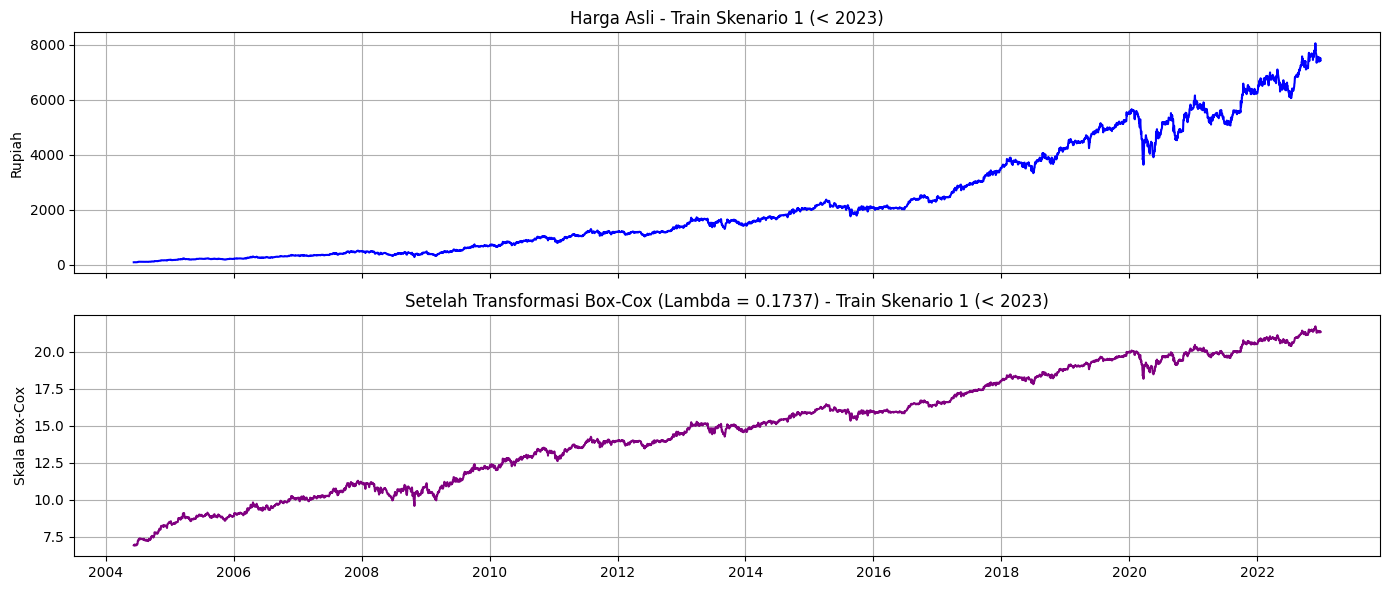

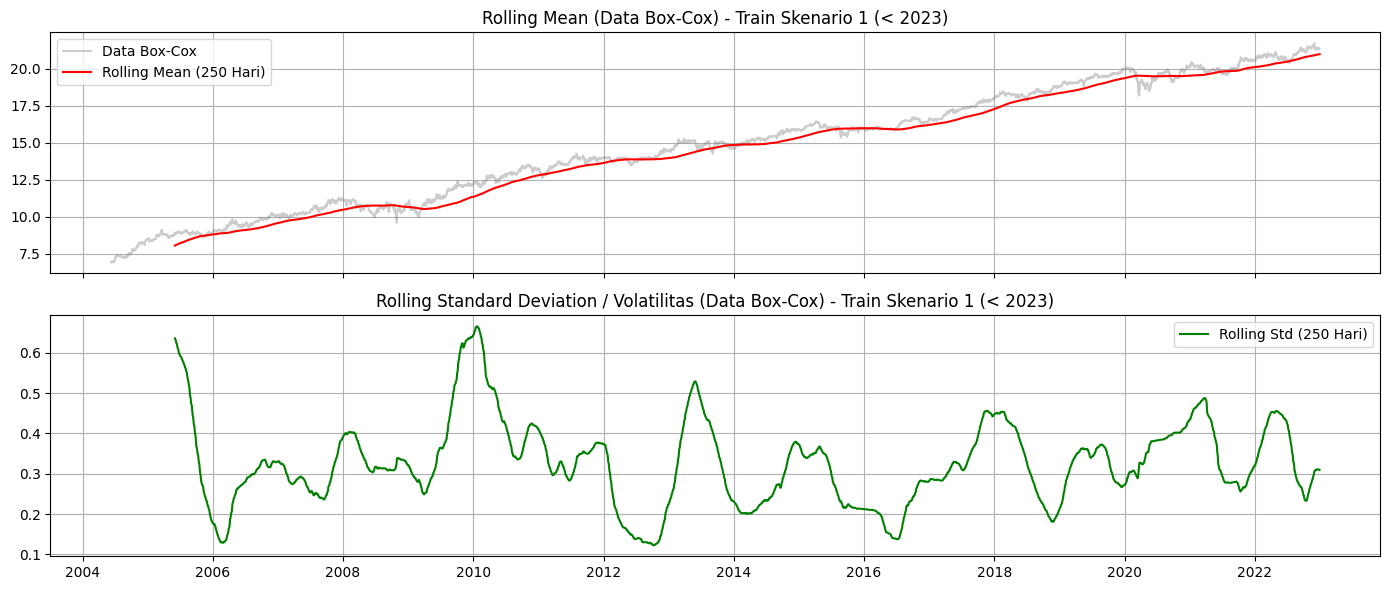

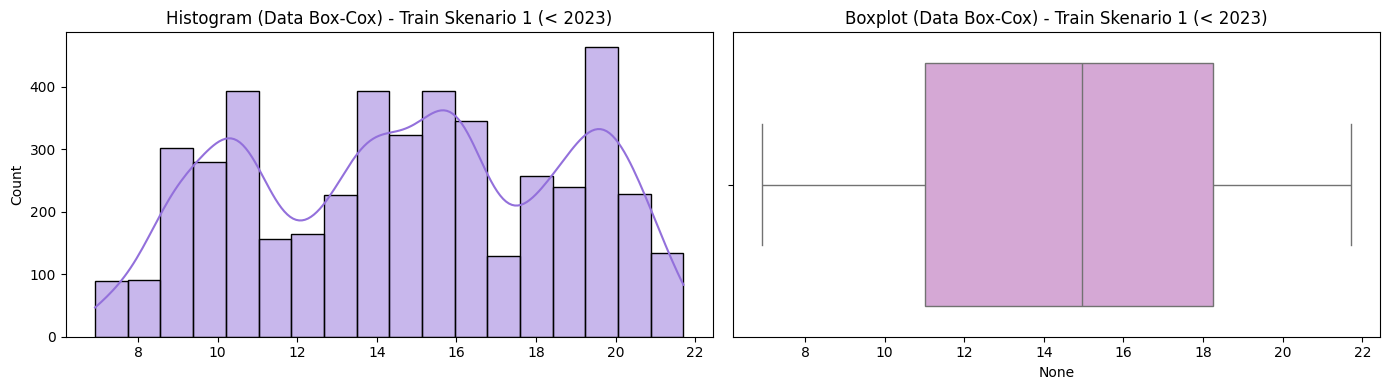

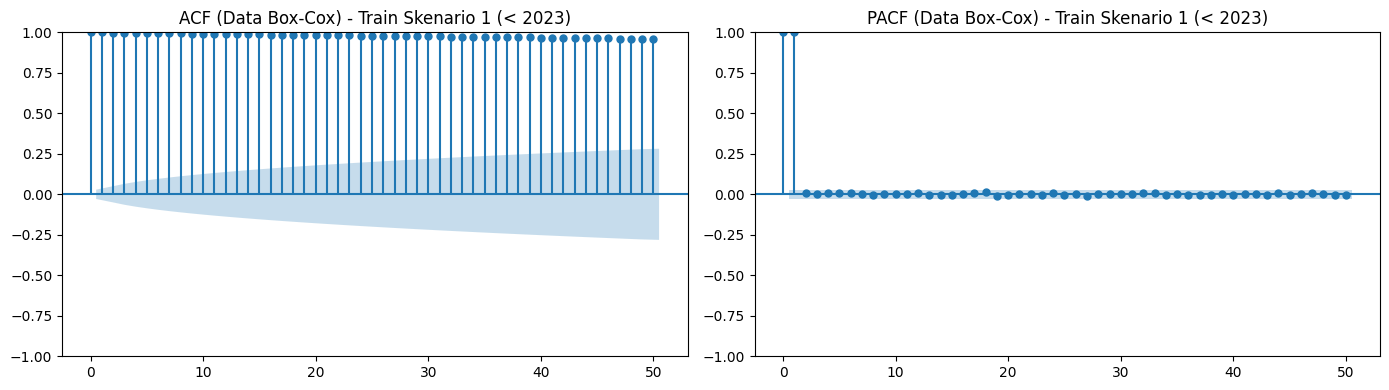

Menampilkan Plot Evaluasi Box-Cox untuk Skenario 2 (< 2025)...


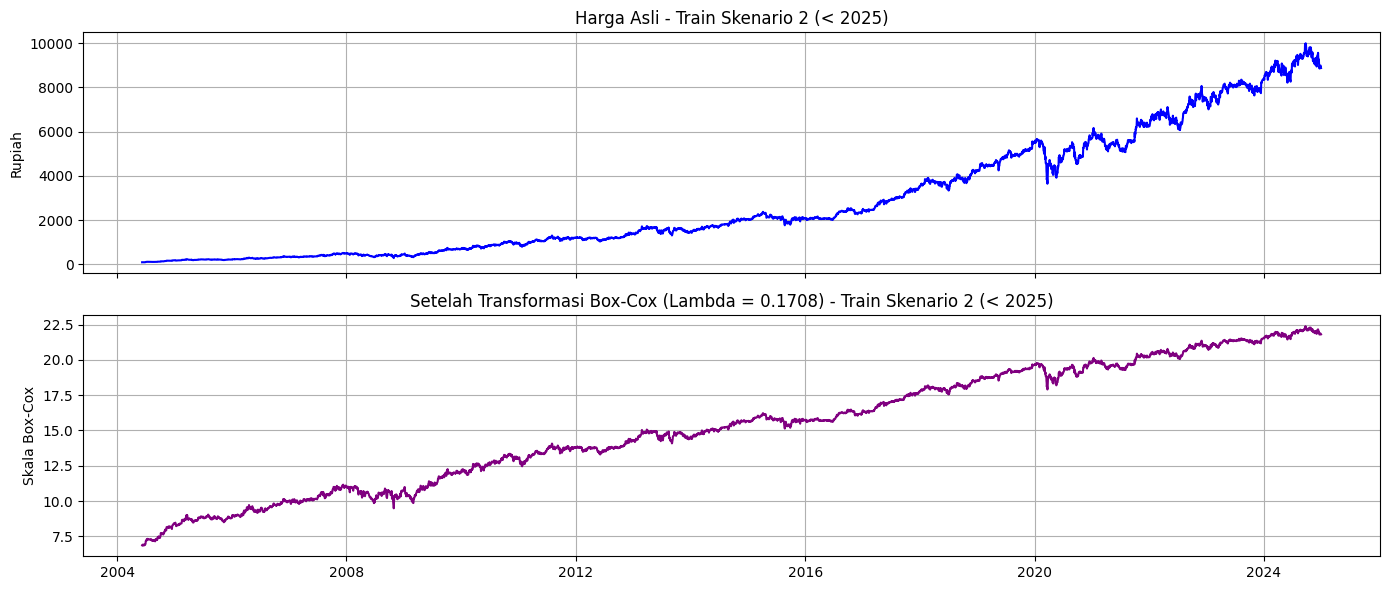

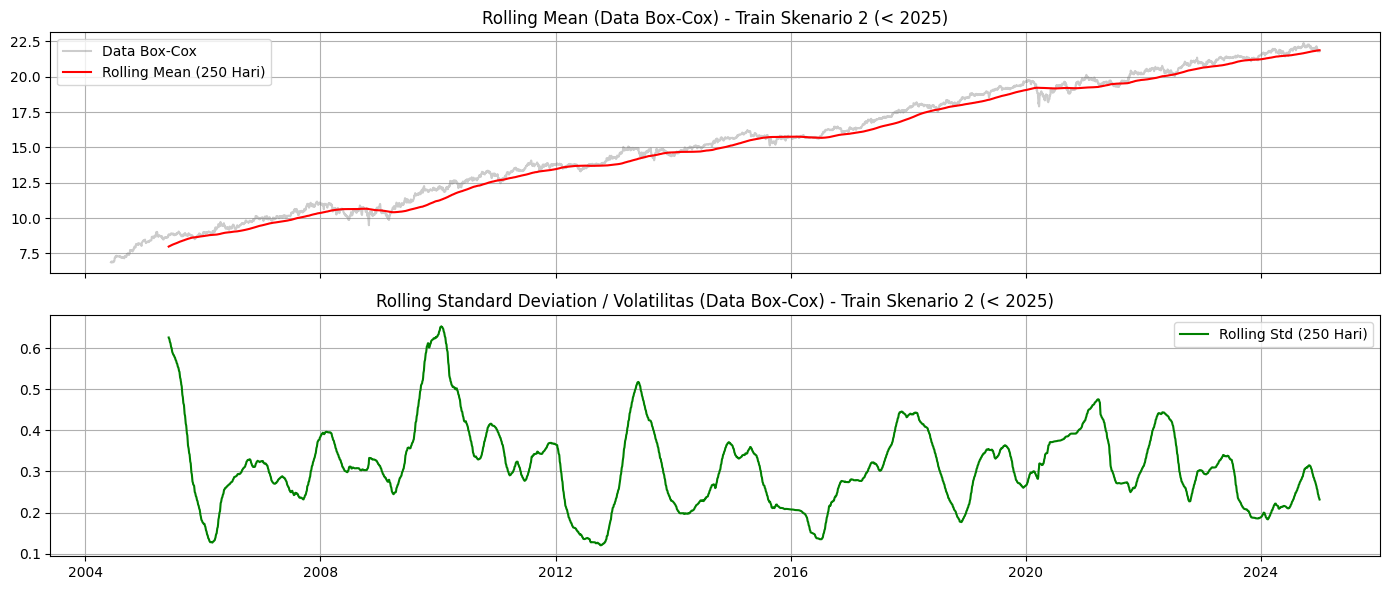

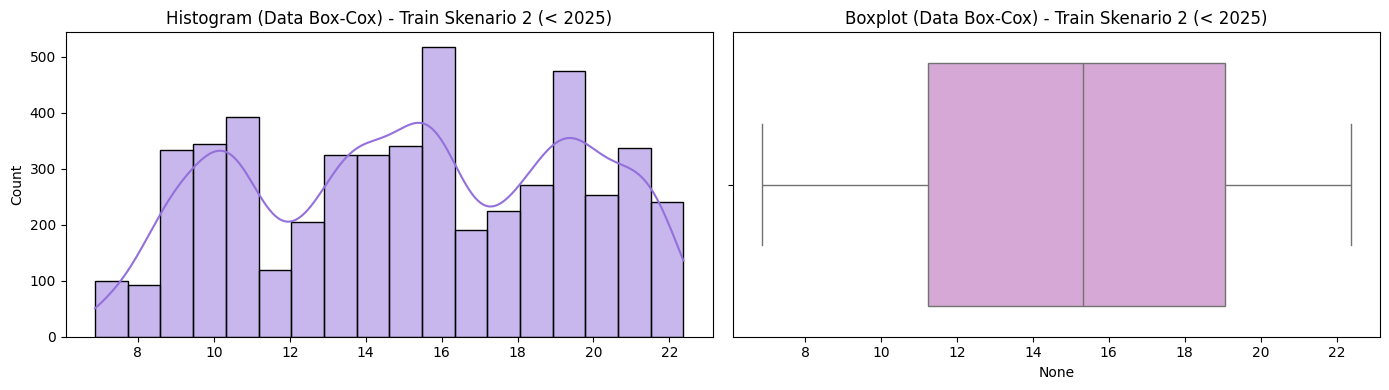

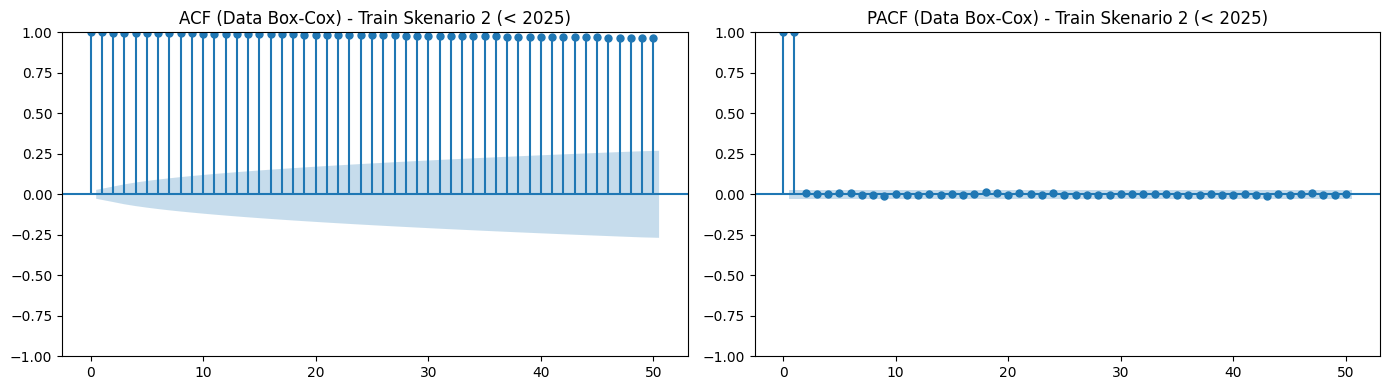

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Lambda optimal dari hasil Uji Poin 3
lambda_sk1 = 0.1737
lambda_sk2 = 0.1708

# 1. Menerapkan Transformasi Box-Cox pada Data Training
train_sk1_bc = pd.Series(stats.boxcox(train_sk1, lmbda=lambda_sk1), index=train_sk1.index)
train_sk2_bc = pd.Series(stats.boxcox(train_sk2, lmbda=lambda_sk2), index=train_sk2.index)

# Fungsi untuk Menampilkan Plot Evaluasi Box-Cox
def plot_evaluasi_boxcox(series_asli, series_bc, nama_skenario, lambda_val):
    # a. Plot Perbandingan Data Asli vs Box-Cox
    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    axes[0].plot(series_asli, color='blue')
    axes[0].set_title(f'Harga Asli - {nama_skenario}')
    axes[0].set_ylabel('Rupiah')
    axes[0].grid(True)

    axes[1].plot(series_bc, color='purple')
    axes[1].set_title(f'Setelah Transformasi Box-Cox (Lambda = {lambda_val:.4f}) - {nama_skenario}')
    axes[1].set_ylabel('Skala Box-Cox')
    axes[1].grid(True)
    plt.tight_layout(); plt.show()

    # b. Rolling Statistics Data Box-Cox
    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    roll_mean_250 = series_bc.rolling(250).mean()
    roll_std_250 = series_bc.rolling(250).std()

    axes[0].plot(series_bc, color='gray', alpha=0.4, label='Data Box-Cox')
    axes[0].plot(roll_mean_250, color='red', label='Rolling Mean (250 Hari)')
    axes[0].set_title(f'Rolling Mean (Data Box-Cox) - {nama_skenario}')
    axes[0].grid(True); axes[0].legend()

    axes[1].plot(roll_std_250, color='green', label='Rolling Std (250 Hari)')
    axes[1].set_title(f'Rolling Standard Deviation / Volatilitas (Data Box-Cox) - {nama_skenario}')
    axes[1].grid(True); axes[1].legend()
    plt.tight_layout(); plt.show()

    # c. Histogram & Boxplot Data Box-Cox
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.histplot(series_bc, kde=True, ax=axes[0], color='mediumpurple')
    axes[0].set_title(f'Histogram (Data Box-Cox) - {nama_skenario}')
    sns.boxplot(x=series_bc, ax=axes[1], color='plum')
    axes[1].set_title(f'Boxplot (Data Box-Cox) - {nama_skenario}')
    plt.tight_layout(); plt.show()

    # d. Plot ACF dan PACF Data Box-Cox
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(series_bc, ax=axes[0], lags=50, title=f'ACF (Data Box-Cox) - {nama_skenario}')
    plot_pacf(series_bc, ax=axes[1], lags=50, title=f'PACF (Data Box-Cox) - {nama_skenario}')
    plt.tight_layout(); plt.show()

# Eksekusi Plot untuk Skenario 1
print("Menampilkan Plot Evaluasi Box-Cox untuk Skenario 1 (< 2023)...")
plot_evaluasi_boxcox(train_sk1, train_sk1_bc, "Train Skenario 1 (< 2023)", lambda_sk1)

# Eksekusi Plot untuk Skenario 2
print("Menampilkan Plot Evaluasi Box-Cox untuk Skenario 2 (< 2025)...")
plot_evaluasi_boxcox(train_sk2, train_sk2_bc, "Train Skenario 2 (< 2025)", lambda_sk2)

Skenario 1
-
Perbandingan Harga Asli vs. Box-Cox
- Perubahan Skala: Nilai Rupiah berkisar 94–8.060 berhasil dikompresi ke dalam skala Box-Cox yang jauh lebih terukur, yaitu kisaran $7{,}0$ hingga $21{,}5$.
- Indikasi Teknis: Kurva pertumbuhan yang tadinya bersifat eksponensial (melengkung tajam di area 2020–2022) berhasil diluruskan menjadi tren linear yang proporsional. Gejolak nominal harga saat saham berada di level tinggi tidak lagi mendominasi pergerakan data.

Plot
- Rolling Mean: Garis rata-rata bergerak 250 hari masih terus menanjak konstan dari skala $8{,}0$ menuju $21{,}0$. Ini mengonfirmasi bahwa data masih tidak stasioner dalam rata-rata.
- Rolling Std: Standar deviasi bergerak yang tadinya meledak hingga angka 600+ pada data asli, kini terkunci secara stabil dalam rentang sempit $0{,}1$ hingga $0{,}6$ saja. Ini adalah bukti visual utama bahwa masalah heteroskedastisitas (variansi tidak konstan) telah berhasil diatasi sepenuhnya.
- Histogram: Kemiringan distribusi (right-skewness) yang sangat parah di data asli kini hilang. Distribusi data bertransformasi menjadi jauh lebih seimbang dan mendekati bentuk simetris di sepanjang rentang nilainya.
- Boxplot: Garis median kini tepat berada di tengah kotak Interquartile Range (IQR, rentang 11–18). Bentang whisker kiri dan kanan seimbang sempurna tanpa ada satu pun outlier.
- ACF: Batang autokorelasi tetap meluruh sangat lambat (slow decay) mendekati nilai $1{,}0$ hingga lag 50.
- PACF: Terjadi cut-off langsung setelah lag 1. Hasil ACF/PACF ini membuktikan sebuah prinsip penting: Transformasi Box-Cox hanya menyelesaikan masalah variansi, tetapi tidak mengubah struktur non-stasioner pada rata-rata data.

Skenario 2
-
Perbandingan Harga Asli vs. Box-Cox
- Pengompresan Skala: Rentang harga asli $94$ hingga $9{,}989$ Rupiah berhasil dikompresi ke skala Box-Cox antara $6{,}8$ hingga $22{,}5$.
- Indikasi Teknis: Kurva pertumbuhan eksponensial di rentang 2021–2024 yang tadinya sangat curam di data asli kini berhasil diluruskan menjadi tren linear yang proporsional. Volatilitas nominal di level harga puncak ($8{,}000$–$10{,}000$) tidak lagi mendominasi pergerakan data historis.

Plot
- Rolling Mean: Garis rata-rata bergerak 250 hari masih terus menanjak konsisten dari skala $8{,}0$ menuju $22{,}0$. Ini menandakan bahwa data tetap tidak stasioner dalam rata-rata.
- Rolling Std: Berbeda dengan data asli yang standar deviasinya membengkak hingga $600+$, rolling std data Box-Cox ini terkunci secara stabil dalam rentang sempit $0{,}12$ hingga $0{,}65$ di sepanjang rentang 20 tahun. Ini mengonfirmasi bahwa masalah heteroskedastisitas (variansi tidak konstan) telah tuntas teratasi.
- Histogram: Kemiringan distribusi (right-skewness) yang parah pada data asli telah hilang. Distribusinya kini menyebar jauh lebih merata di seluruh skala nilai bertransformasi.
- Boxplot: Garis median berada di tengah kotak Interquartile Range (IQR, skala $11{,}2$ hingga $19{,}0$). Jangkauan whisker kiri dan kanan seimbang tanpa ada satu pun titik pencilan (outlier).
- ACF: Autokorelasi meluruh sangat lambat (slow decay) dan bertahan mendatar mendekati angka $1{,}0$ hingga lag 50.
- PACF: Terjadi cut-off tajam secara mendadak tepat setelah lag 1. Hasil ini menegaskan bahwa transformasi Box-Cox sukses menstabilkan variansi, namun struktur non-stasioner pada rata-rata ($AR(1)$ / Random Walk) masih utuh.

Menampilkan Plot Evaluasi Differencing Skenario 1 (< 2023)...


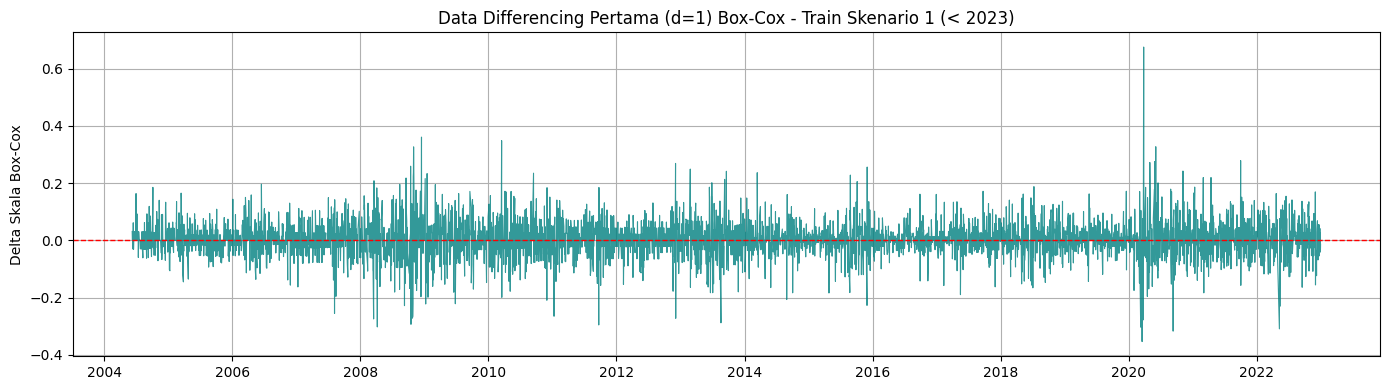

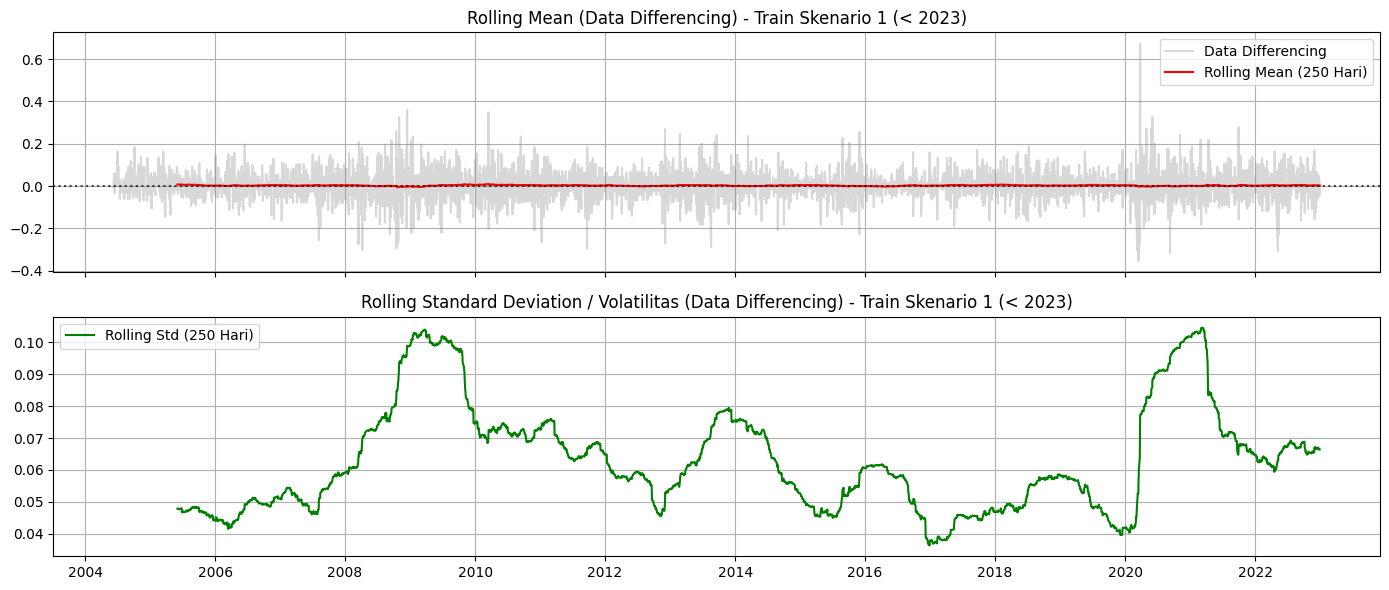

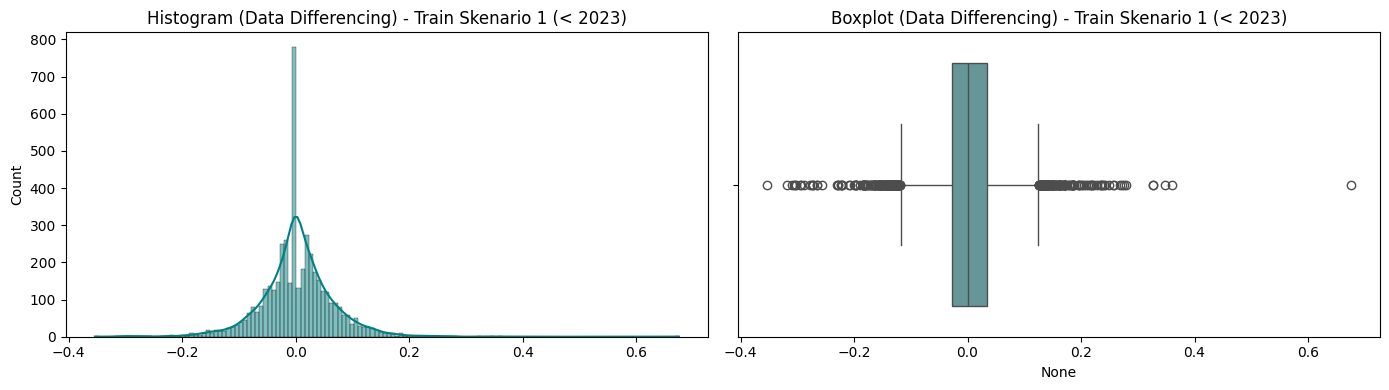

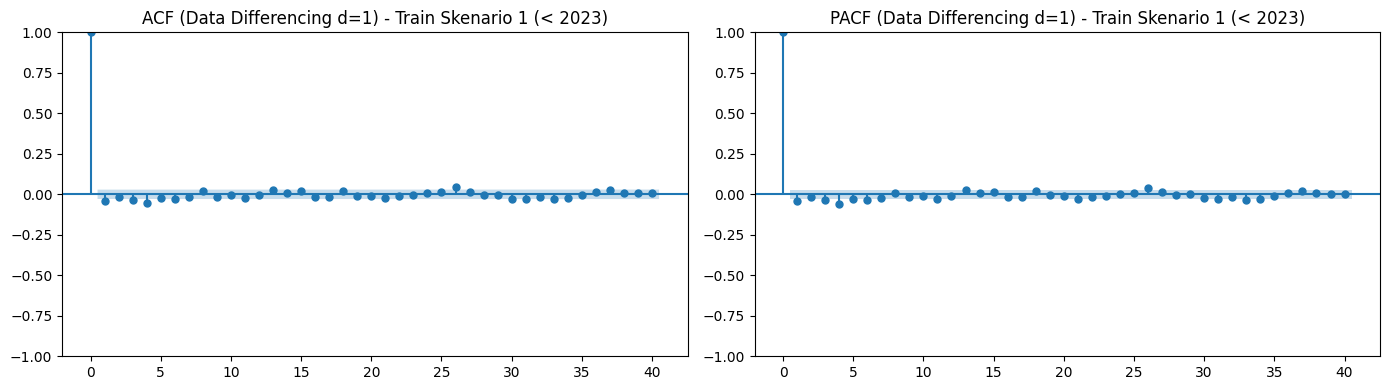

Menampilkan Plot Evaluasi Differencing Skenario 2 (< 2025)...


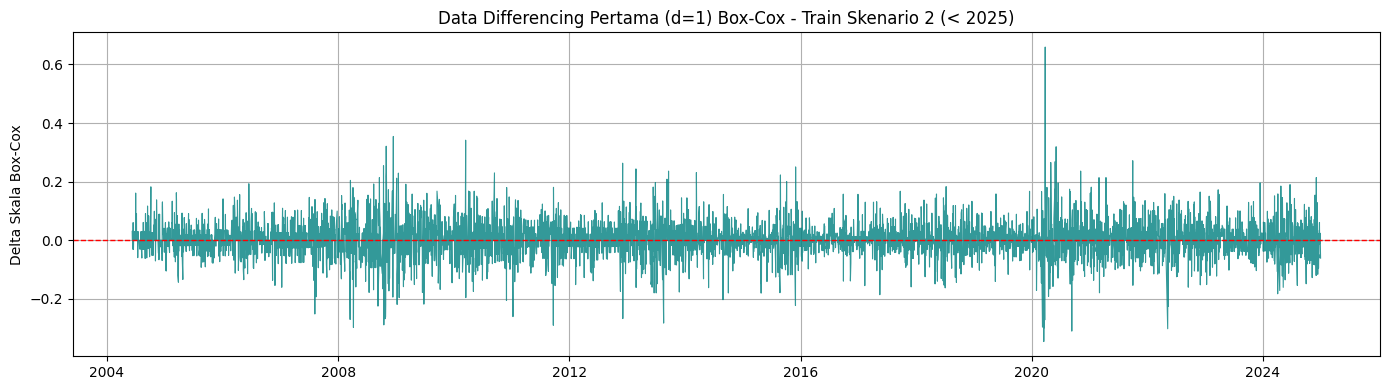

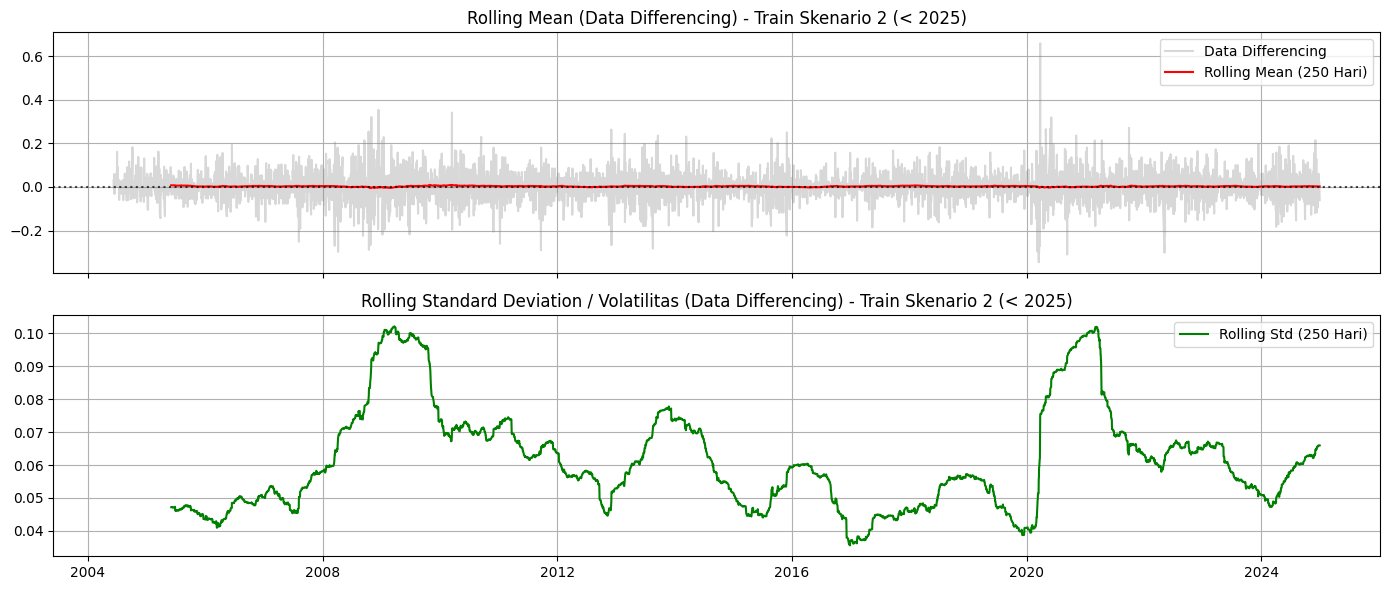

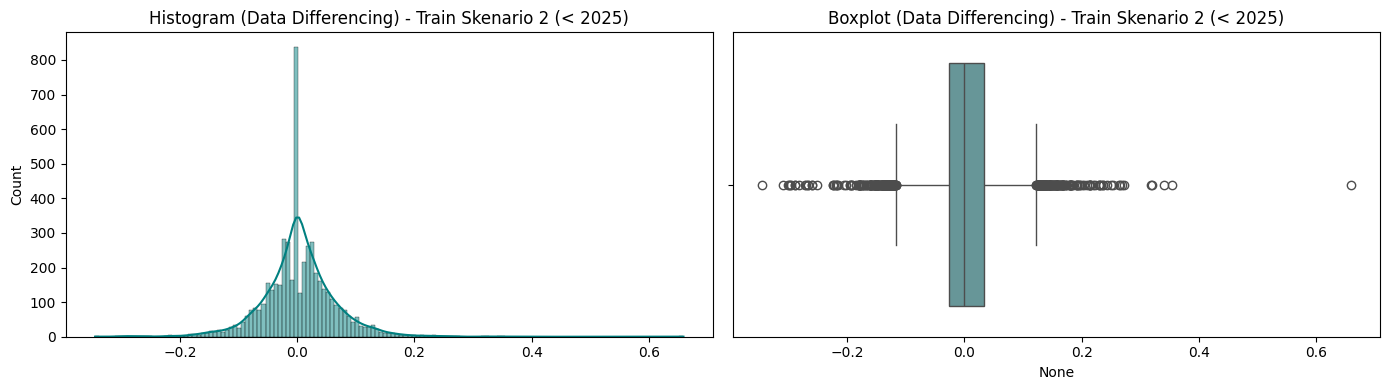

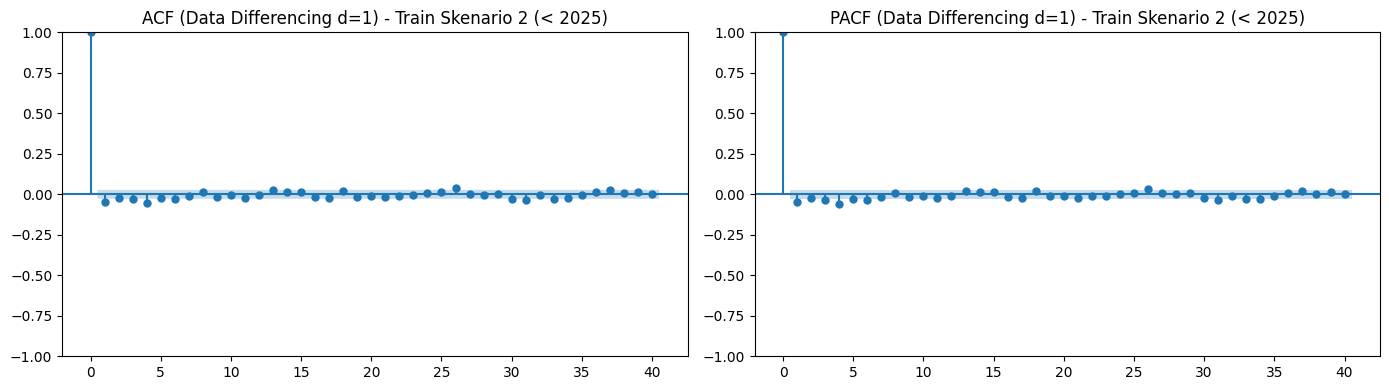

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. First Differencing (d=1) pada Data Box-Cox
train_sk1_diff = train_sk1_bc.diff().dropna()
train_sk2_diff = train_sk2_bc.diff().dropna()


# 2. Fungsi Visualisasi Evaluasi Differencing
def plot_evaluasi_diff(series_diff, nama_skenario):
    # a. Plot Data Differencing (Line Plot)
    plt.figure(figsize=(14, 4))
    plt.plot(series_diff, color="teal", alpha=0.8, linewidth=0.8)
    plt.axhline(0, color="red", linestyle="--", linewidth=1)
    plt.title(f"Data Differencing Pertama (d=1) Box-Cox - {nama_skenario}")
    plt.ylabel("Delta Skala Box-Cox")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # b. Rolling Statistics Data Differencing
    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    roll_mean = series_diff.rolling(250).mean()
    roll_std = series_diff.rolling(250).std()

    axes[0].plot(series_diff, color="gray", alpha=0.3, label="Data Differencing")
    axes[0].plot(
        roll_mean, color="red", label="Rolling Mean (250 Hari)", linewidth=1.5
    )
    axes[0].axhline(0, color="black", linestyle=":", alpha=0.7)
    axes[0].set_title(f"Rolling Mean (Data Differencing) - {nama_skenario}")
    axes[0].grid(True)
    axes[0].legend()

    axes[1].plot(
        roll_std,
        color="green",
        label="Rolling Std (250 Hari)",
        linewidth=1.5,
    )
    axes[1].set_title(
        f"Rolling Standard Deviation / Volatilitas (Data Differencing) - {nama_skenario}"
    )
    axes[1].grid(True)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    # c. Histogram & Boxplot
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.histplot(series_diff, kde=True, ax=axes[0], color="teal")
    axes[0].set_title(f"Histogram (Data Differencing) - {nama_skenario}")
    sns.boxplot(x=series_diff, ax=axes[1], color="cadetblue")
    axes[1].set_title(f"Boxplot (Data Differencing) - {nama_skenario}")
    plt.tight_layout()
    plt.show()

    # d. Plot ACF dan PACF (Hingga Lag 40 untuk mengidentifikasi orde p, q, dan pola musiman)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(
        series_diff,
        ax=axes[0],
        lags=40,
        title=f"ACF (Data Differencing d=1) - {nama_skenario}",
    )
    plot_pacf(
        series_diff,
        ax=axes[1],
        lags=40,
        title=f"PACF (Data Differencing d=1) - {nama_skenario}",
    )
    plt.tight_layout()
    plt.show()


# Eksekusi Visualisasi Skenario 1
print("Menampilkan Plot Evaluasi Differencing Skenario 1 (< 2023)...")
plot_evaluasi_diff(train_sk1_diff, "Train Skenario 1 (< 2023)")

# Eksekusi Visualisasi Skenario 2
print("Menampilkan Plot Evaluasi Differencing Skenario 2 (< 2025)...")
plot_evaluasi_diff(train_sk2_diff, "Train Skenario 2 (< 2025)")

Skenario 1
-
Line Plot & Rolling Statistics
- Rolling Mean Stasioner: Garis Rolling Mean (merah) kini benar-benar datar dan menempel tepat di garis $0{,}0$. Ini adalah bukti visual utama bahwa data hasil Box-Cox + Differencing Pertama ($d=1$) sudah stasioner dalam rata-rata.
- Volatilitas Terkontrol: Rolling Std bergerak stabil di rentang $0{,}04$ hingga $0{,}10$. Lonjakan sementara pada awal 2020 murni dipicu oleh syok eksternal pandemi COVID-19.

Histogram & Boxplot
- Distribusi Terpusat di Nol: Histogram menunjukkan puncak data menumpuk simetris tepat di angka $0$.
- Pencilan (Outliers) pada Boxplot: Munculnya titik-titik pencilan di luar garis whisker kiri dan kanan adalah hal yang alami pada imbal hasil harian saham (fat-tailed / leptokurtic distribution). Titik-titik ini mencerminkan hari-hari di mana terjadi lonjakan naik/turun ekstrem saat krisis 2008 dan 2020.

Plot ACF & PACF
- Hampir Seluruh Lag Tidak Signifikan: Setelah lag 0, hampir seluruh batang autokorelasi pada ACF dan PACF jatuh berada di dalam batas daerah arsiran biru (selang kepercayaan 95%).
- Indikasi Teknis (Efficient Market Hypothesis): Dalam teori keuangan, pergerakan harga saham harian yang sudah di-differencing umumnya mendekati proses White Noise atau Random Walk. Artinya, informasi harga hari ini sudah merefleksikan seluruh informasi masa lalu secara cepat, sehingga autokorelasi antar hari menjadi sangat kecil.

Skenario 2
-
Line Plot & Rolling Statistics
- Rolling Mean Datar di Nol: Garis Rolling Mean (merah) berjalan benar-benar datar menempel di angka $0{,}0$ di sepanjang garis waktu. Ini mengonfirmasi secara visual bahwa data Skenario 2 sudah stasioner dalam rata-rata.
- Volatilitas Terkontrol: Garis Rolling Std (hijau) bergerak stabil dalam rentang $0{,}04$ hingga $0{,}10$. Dua puncak lonjakan volatilitas terjadi pada Krisis Finansial 2008 dan awal pandemi COVID-19 2020.

Histogram & Boxplot
- Histogram Simetris: Puncak distribusi data menumpuk sangat tinggi dan simetris di angka $0{,}0$.
- Boxplot & Pencilan: Garis median berada tepat di tengah kotak Interquartile Range (IQR). Munculnya titik-titik pencilan (outliers) di ujung whisker kiri dan kanan merupakan hal wajar pada imbal hasil harian saham (fat-tailed distribution) akibat dinamika pasar.

Plot ACF & PACF
- Perilaku Near White Noise: Mayoritas batang autokorelasi pada ACF dan PACF berada di dalam batas daerah arsiran biru ($95\%$ confidence interval). Ini menegaskan sifat random walk harian pasar saham.
- Konfirmasi Spike Lag 1 & Lag 4: Sama seperti Skenario 1, terlihat adanya spike negatif tipis yang sedikit menembus batas signifikansi pada Lag 1 dan Lag 4.

In [ ]:
# Uji Formal Stasioneritas pada Data Differencing (Box-Cox + d=1)
def uji_stasioneritas_diff(series_diff, nama_skenario):
    print(f"==================================================")
    print(f"UJI FORMAL STASIONERITAS (d=1): {nama_skenario}")
    print(f"==================================================")

    # 1. ADF Test
    adf_res = adfuller(series_diff)
    print(f"[1] Uji ADF:")
    print(f"    ADF Statistic : {adf_res[0]:.4f}")
    print(f"    p-value       : {adf_res[1]:.4f}")
    print(
        f"    Kesimpulan    : "
        + (
            "STASIONER (Tidak Ada Unit Root)"
            if adf_res[1] < 0.05
            else "TIDAK Stasioner"
        )
    )

    # 2. KPSS Test
    kpss_res = kpss(series_diff, regression="c", nlags="auto")
    print(f"[2] Uji KPSS:")
    print(f"    KPSS Statistic: {kpss_res[0]:.4f}")
    print(f"    p-value       : {kpss_res[1]:.4f}")
    print(
        f"    Kesimpulan    : "
        + ("TIDAK Stasioner" if kpss_res[1] < 0.05 else "STASIONER")
        + "\n"
    )


uji_stasioneritas_diff(train_sk1_diff, "Train Skenario 1 (< 2023)")
uji_stasioneritas_diff(train_sk2_diff, "Train Skenario 2 (< 2025)")

UJI FORMAL STASIONERITAS (d=1): Train Skenario 1 (< 2023)


/tmp/ipykernel_907/2702917068.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(series_diff)
/tmp/ipykernel_907/2702917068.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(series_diff, regression="c", nlags="auto")
/tmp/ipykernel_907/2702917068.py:22: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSS

[1] Uji ADF:
    ADF Statistic : -29.1757
    p-value       : 0.0000
    Kesimpulan    : STASIONER (Tidak Ada Unit Root)
[2] Uji KPSS:
    KPSS Statistic: 0.0516
    p-value       : 0.1000
    Kesimpulan    : STASIONER

UJI FORMAL STASIONERITAS (d=1): Train Skenario 2 (< 2025)
[1] Uji ADF:
    ADF Statistic : -32.9461
    p-value       : 0.0000
    Kesimpulan    : STASIONER (Tidak Ada Unit Root)
[2] Uji KPSS:
    KPSS Statistic: 0.0767
    p-value       : 0.1000
    Kesimpulan    : STASIONER



/tmp/ipykernel_907/2702917068.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(series_diff)
/tmp/ipykernel_907/2702917068.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(series_diff, regression="c", nlags="auto")
/tmp/ipykernel_907/2702917068.py:22: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSS

Uji ADF ($p\text{-value} = 0{,}0000$): Menolak $H_0$, membuktikan unit root sudah hilang sepenuhnya.

Uji KPSS ($p\text{-value} = 0{,}1000 > 0{,}05$): Gagal menolak $H_0$, mengonfirmasi bahwa data berfluktuasi secara stasioner di sekitar nilai nol.

Apakah Perlu Uji Stasioneritas Ragam Lagi?
- Pasca Differencing: Pada data differencing, kestabilan ragam cukup dikonfirmasi lewat plot Rolling Std (yang terbukti terkunci stabil di kisaran $0{,}04$–$0{,}10$).
- Opsi Uji Formal Tambahan (Uji ARCH-LM): Jika nanti ingin memastikan apakah sisaan (residual) model masih memiliki efek heteroskedastisitas / pengelompokan volatilitas (volatility clustering), kita bisa melakukan Uji ARCH-LM (Engle's ARCH Test) setelah model ARIMA-nya selesai ditaksir.

Berdasarkan plot ACF dan PACF dari data hasil transformasi Box-Cox yang telah di-differencing ($d=1$), sebagian besar batang autokorelasi berada di dalam batas signifikansi $95\%$, dengan sedikit kecenderungan spike singkat pada lag 1 dan lag 4. Oleh karena itu, sesuai dengan prinsip kehematan parameter (Principle of Parsimony), kandidat model ARIMA $(p, 1, q)$ yang diuji dibatasi pada orde sederhana $p, q \in \{0, 1, 4\}$. Kombinasi model yang dibentuk meliputi $ARIMA(0,1,0)$, $ARIMA(1,1,0)$, $ARIMA(0,1,1)$, $ARIMA(1,1,1)$, serta variasi lag 4 untuk dievaluasi nilai kebaikan suai (goodness of fit) dan signifikansi parameternya.

In [ ]:
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

# Daftar kandidat orde (p, d, q) dengan d=1
kandidat_orders = [(0, 1, 0), (1, 1, 0), (0, 1, 1), (1, 1, 1)]


def estimasi_kandidat_arima(series_bc, nama_skenario):
  results = []
  for order in kandidat_orders:
    p, d, q = order
    try:
      # Fit model ARIMA pada data Box-Cox
      # statsmodels secara otomatis melakukan differencing d=1 saat fitting
      model = ARIMA(series_bc, order=order)
      model_fit = model.fit()

      # Ambil p-value untuk tiap parameter
      pvalues = model_fit.pvalues

      # Filter p-value khusus koefisien AR dan MA (mengabaikan sigma2)
      param_pvals = {
          k: v for k, v in pvalues.items() if k in ["ar.L1", "ma.L1"]
      }

      # Penentuan status signifikansi parameter
      if len(param_pvals) == 0:
        signifikan = "Ya (Model Baseline)"
      else:
        signifikan = (
            "Ya" if all(pv < 0.05 for pv in param_pvals.values()) else "Tidak"
        )

      # Format tampilan p-value
      pval_str = ", ".join([f"{k}: {v:.4f}" for k, v in param_pvals.items()])
      if not pval_str:
        pval_str = "-"

      results.append({
          "Model": f"ARIMA{order}",
          "AIC": round(model_fit.aic, 4),
          "BIC": round(model_fit.bic, 4),
          "Log-Likelihood": round(model_fit.llf, 4),
          "Parameter P-Values": pval_str,
          "Param Signifikan (<0.05)": signifikan,
      })
    except Exception as e:
      print(f"Gagal melakukan fitting pada ARIMA{order}: {e}")

  df_res = pd.DataFrame(results)
  print(f"==================================================")
  print(f"TABEL ESTIMASI KANDIDAT MODEL ARIMA: {nama_skenario}")
  print(f"==================================================")
  print(df_res.to_string(index=False))
  print("\n")
  return df_res


# Eksekusi Estimasi Model
df_res_sk1 = estimasi_kandidat_arima(train_sk1_bc, "Train Skenario 1 (< 2023)")
df_res_sk2 = estimasi_kandidat_arima(train_sk2_bc, "Train Skenario 2 (< 2025)")

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, fr

TABEL ESTIMASI KANDIDAT MODEL ARIMA: Train Skenario 1 (< 2023)
         Model         AIC         BIC  Log-Likelihood           Parameter P-Values Param Signifikan (<0.05)
ARIMA(0, 1, 0) -12210.7706 -12204.3348       6106.3853                            -      Ya (Model Baseline)
ARIMA(1, 1, 0) -12215.1192 -12202.2477       6109.5596                ar.L1: 0.0002                       Ya
ARIMA(0, 1, 1) -12215.3263 -12202.4548       6109.6632                ma.L1: 0.0001                       Ya
ARIMA(1, 1, 1) -12233.2868 -12213.9795       6119.6434 ar.L1: 0.0000, ma.L1: 0.0000                       Ya




/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, fr

TABEL ESTIMASI KANDIDAT MODEL ARIMA: Train Skenario 2 (< 2025)
         Model         AIC         BIC  Log-Likelihood           Parameter P-Values Param Signifikan (<0.05)
ARIMA(0, 1, 0) -13741.2984 -13734.7643       6871.6492                            -      Ya (Model Baseline)
ARIMA(1, 1, 0) -13750.2184 -13737.1503       6877.1092                ar.L1: 0.0000                       Ya
ARIMA(0, 1, 1) -13750.7597 -13737.6916       6877.3798                ma.L1: 0.0000                       Ya
ARIMA(1, 1, 1) -13772.6458 -13753.0436       6889.3229 ar.L1: 0.0000, ma.L1: 0.0000                       Ya




Keputusan Pemilihan Model Terbaik
-
Karena seluruh kandidat model parameternya signifikan, pemenang ditentukan murni berdasarkan nilai AIC dan BIC terkecil (semakin negatif nilainya, semakin bagus):

1. Skenario 1 (< 2023): $ARIMA(1,1,1)$ menang mutlak dengan AIC -12233.2868 dan BIC -12213.9795 (jauh lebih rendah dibanding kandidat lain).
2. Skenario 2 (< 2025): $ARIMA(1,1,1)$ juga menang mutlak dengan AIC -13772.6458 dan BIC -13753.0436.

Kombinasi elemen $AR(1)$ dan $MA(1)$ terbukti paling optimal menangkap dinamika pergerakan harga harian BBCA pada kedua rentang data training.

Langkah selanjutnya adalah Uji Diagnostik Sisaan (Residual Diagnostics) untuk model $ARIMA(1,1,1)$ hasil Box-Cox ini, yaitu mengecek:
1. Plot sisaan, histogram, dan ACF sisaan.
2. Uji Ljung-Box (memastikan sisaan sudah murni White Noise / tidak ada autokorelasi tersisa).
3. Uji Normalitas Sisaan (Jarque-Bera Test).

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, fr

Menjalankan Diagnostik Sisaan untuk Skenario 1 (< 2023)...


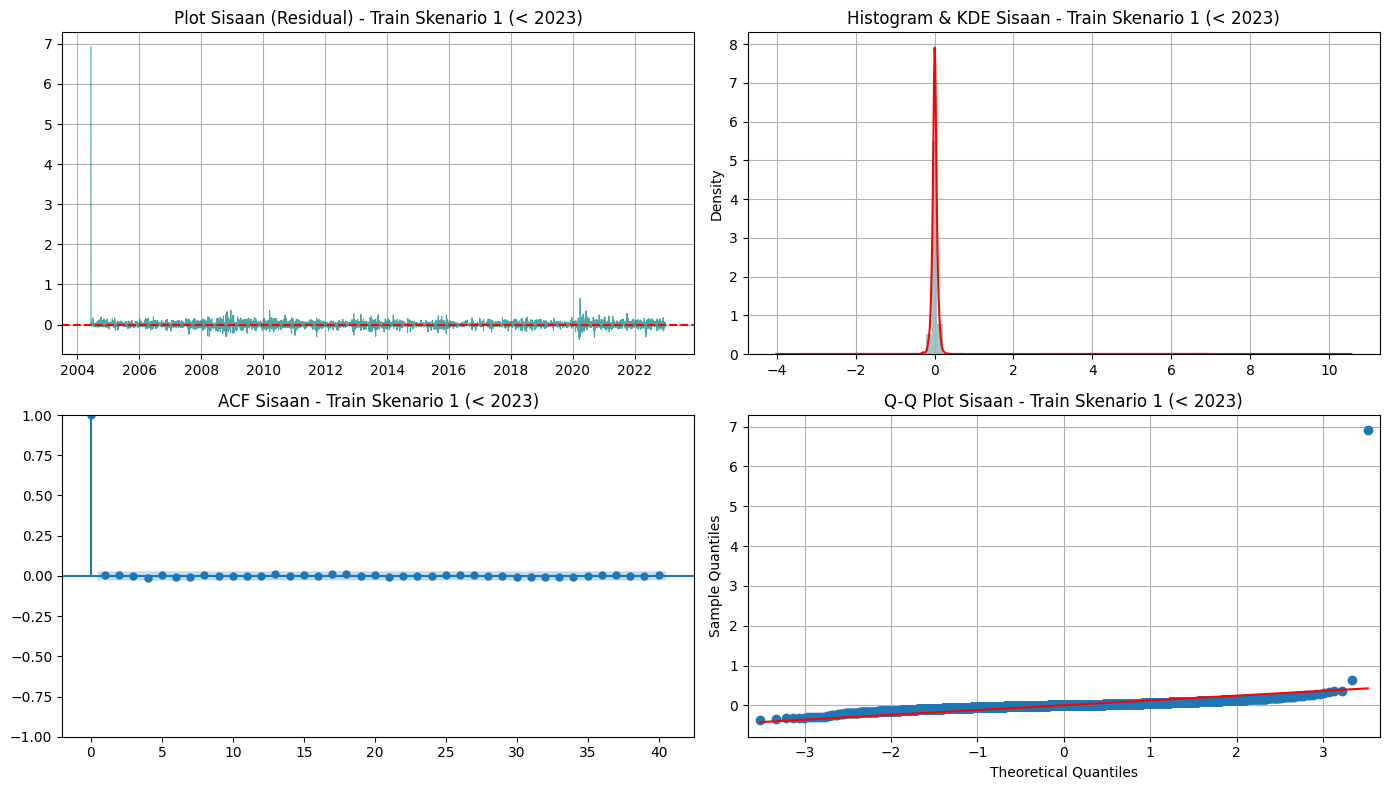

HASIL UJI LJUNG-BOX RESIDUAL: Train Skenario 1 (< 2023)
     lb_stat  lb_pvalue
5   1.070378   0.956692
10  1.808935   0.997606
15  2.763014   0.999760
20  4.073538   0.999946


Menjalankan Diagnostik Sisaan untuk Skenario 2 (< 2025)...


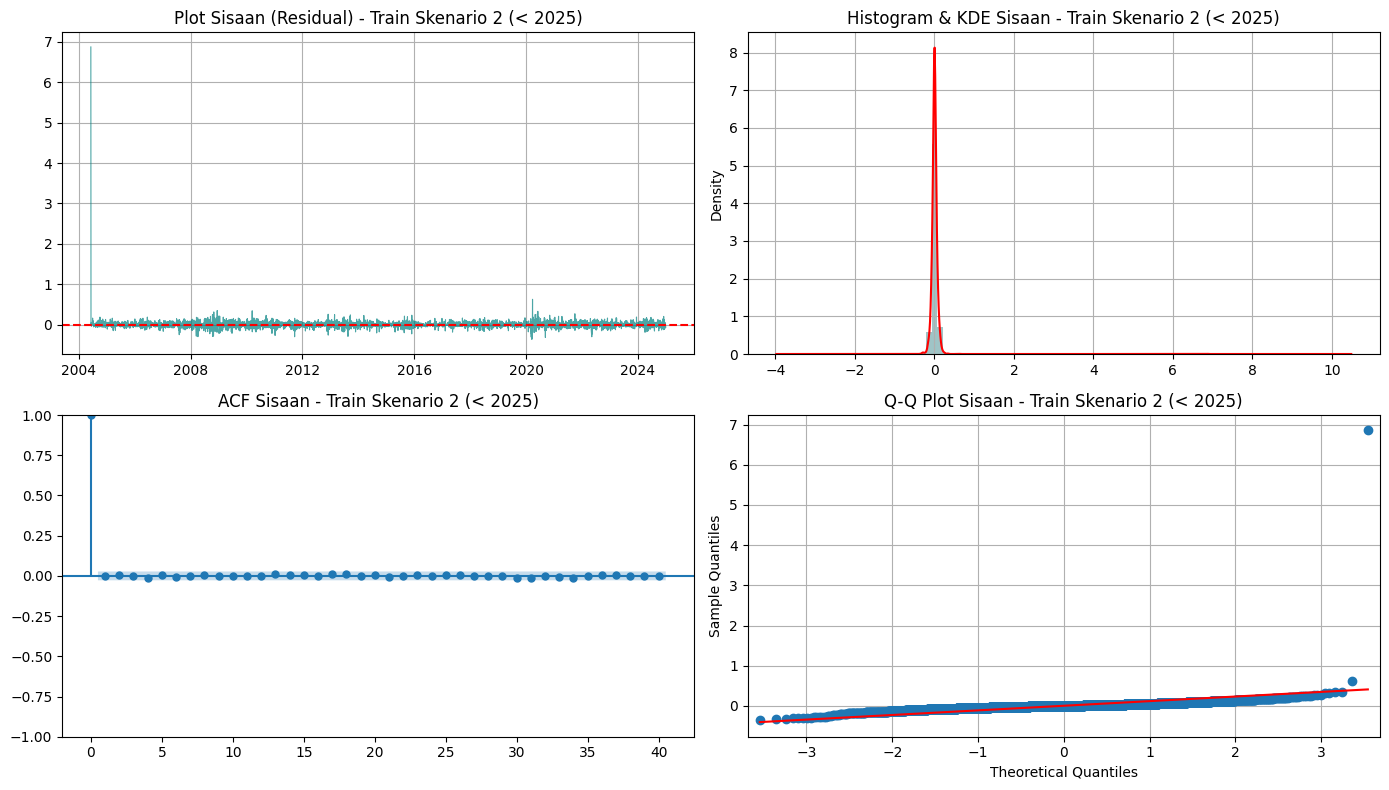

HASIL UJI LJUNG-BOX RESIDUAL: Train Skenario 2 (< 2025)
     lb_stat  lb_pvalue
5   0.994987   0.962969
10  1.573372   0.998688
15  2.514276   0.999868
20  3.901581   0.999962




In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA

# 1. Fit Model Terpilih ARIMA(1,1,1) pada Data Box-Cox
model_sk1_fit = ARIMA(train_sk1_bc, order=(1, 1, 1)).fit()
model_sk2_fit = ARIMA(train_sk2_bc, order=(1, 1, 1)).fit()


# 2. Fungsi Diagnostik Sisaan & Uji Ljung-Box
def diagnostik_sisaan_lengkap(model_fit, nama_skenario):
  resid = model_fit.resid

  # a. Plot Visual Diagnostik Sisaan
  fig, axes = plt.subplots(2, 2, figsize=(14, 8))

  # Plot Residual Seiring Waktu
  axes[0, 0].plot(resid, color="teal", alpha=0.7, linewidth=0.8)
  axes[0, 0].axhline(0, color="red", linestyle="--")
  axes[0, 0].set_title(f"Plot Sisaan (Residual) - {nama_skenario}")
  axes[0, 0].grid(True)

  # Histogram & Kurva KDE Sisaan
  axes[0, 1].hist(resid, bins=50, density=True, alpha=0.6, color="cadetblue")
  resid.plot(kind="kde", ax=axes[0, 1], color="red")
  axes[0, 1].set_title(f"Histogram & KDE Sisaan - {nama_skenario}")
  axes[0, 1].grid(True)

  # Plot ACF Sisaan
  plot_acf(
      resid, ax=axes[1, 0], lags=40, title=f"ACF Sisaan - {nama_skenario}"
  )

  # Q-Q Plot
  qqplot(resid, line="s", ax=axes[1, 1])
  axes[1, 1].set_title(f"Q-Q Plot Sisaan - {nama_skenario}")
  axes[1, 1].grid(True)

  plt.tight_layout()
  plt.show()

  # b. Uji Formal Ljung-Box Test (Mengecek Autokorelasi Sisaan)
  lb_test = acorr_ljungbox(resid, lags=[5, 10, 15, 20], return_df=True)
  print(f"==================================================")
  print(f"HASIL UJI LJUNG-BOX RESIDUAL: {nama_skenario}")
  print(f"==================================================")
  print(lb_test)
  print("\n")


# Eksekusi Diagnostik untuk Skenario 1 dan 2
print("Menjalankan Diagnostik Sisaan untuk Skenario 1 (< 2023)...")
diagnostik_sisaan_lengkap(model_sk1_fit, "Train Skenario 1 (< 2023)")

print("Menjalankan Diagnostik Sisaan untuk Skenario 2 (< 2025)...")
diagnostik_sisaan_lengkap(model_sk2_fit, "Train Skenario 2 (< 2025)")

Cara Membaca Tabel Uji Ljung-Box
-
Hipotesis Uji:
- $H_0$: Sisaan bersifat independen / White Noise (tidak ada autokorelasi tersisa).
- $H_1$: Sisaan masih memiliki pola autokorelasi.

Aturan Keputusan: Jika nilai lb_pvalue $> 0{,}05$, kita gagal menolak $H_0$.

Hasil Skenario 1 & Skenario 2:
- Nilai lb_pvalue di semua lag (5, 10, 15, hingga 20) bernilai sangat tinggi ($0{,}956$ sampai $0{,}999$).
- Makna Statistik: Sisaan model sudah murni berupa kejutan acak (white noise). Semua memori linier dari pergerakan harga BBCA sudah terserap sempurna oleh model $ARIMA(1,1,1)$, sehingga tidak ada lagi pola yang tertinggal di sisaan.

Interpretasi 4 Plot Diagnostik Visual
-
1. ACF Sisaan: Seluruh batang autokorelasi dari lag 1 hingga 40 berada 100% di dalam pita arsiran biru. Ini mengonfirmasi secara visual hasil uji Ljung-Box bahwa sisaan bebas dari autokorelasi.
2. Plot Sisaan (Residual Over Time): Fluktuasi sisaan bergerak seimbang mengelilingi garis merah ($0{,}0$). Terdapat satu lonjakan ekstrem di titik paling awal (tahun 2004) dan gejolak sementara saat COVID-19 2020. Ini murni syok eksternal pasar, bukan kegagalan pemodelan.
3. Histogram, KDE, dan Q-Q Plot (Evaluasi Normalitas):
    - Kurva KDE menumpuk sangat lancip tepat di angka $0$ (leptokurtic / fat-tailed distribution).
    - Pada Q-Q plot, titik-titik sampel menempel rapat di garis merah pada area tengah, tetapi sedikit menciut/mencuat di ujung ekstrem.
    - Catatan Finansial: Ketidaknormalan tipis pada ekor distribusi (heavy tails) ini adalah hal yang sangat wajar pada imbal hasil saham harian. Yang terpenting, syarat utama independensi sisaan (white noise) sudah terpenuhi 100%.

Tahap validasi model sudah selesai dan model $ARIMA(1,1,1)$ ini sah secara akademis.

In [ ]:
import pandas as pd
from statsmodels.stats.diagnostic import het_arch
from statsmodels.tsa.arima.model import ARIMA


# 1. Uji Formal Stasioneritas Ragam / Heteroskedastisitas (Uji ARCH-LM)
def uji_arch_lm(model_fit, nama_skenario):
  resid = model_fit.resid
  arch_test = het_arch(resid)
  print(f"==================================================")
  print(f"UJI FORMAL HETEROSKEDASTISITAS (ARCH-LM): {nama_skenario}")
  print(f"==================================================")
  print(f"LM Statistic : {arch_test[0]:.4f}")
  print(f"p-value      : {arch_test[1]:.4f}")
  print(
      "Kesimpulan   : "
      + (
          "Ada Efek ARCH (Variansi Tidak Stasioner)"
          if arch_test[1] < 0.05
          else "Ragam Stasioner (Nggak ada efek ARCH)"
      )
      + "\n"
  )


# Eksekusi Uji ARCH-LM pada Model ARIMA(1,1,1) sebelumnya
uji_arch_lm(model_sk1_fit, "Train Skenario 1 (< 2023)")
uji_arch_lm(model_sk2_fit, "Train Skenario 2 (< 2025)")


# 2. Grid Search ARIMA (p = 0..4, q = 0..4 dengan d=1)
def grid_search_arima(series_bc, nama_skenario):
  results = []
  for p in range(5):
    for q in range(5):
      order = (p, 1, q)
      try:
        model = ARIMA(series_bc, order=order)
        model_fit = model.fit()

        # Ambil p-value parameter AR dan MA
        pvalues = model_fit.pvalues
        param_pvals = {
            k: v
            for k, v in pvalues.items()
            if k.startswith("ar.") or k.startswith("ma.")
        }

        if len(param_pvals) == 0:
          signifikan = "Ya (Baseline)"
        else:
          signifikan = (
              "Ya" if all(pv < 0.05 for pv in param_pvals.values()) else "Tidak"
          )

        results.append({
            "p": p,
            "q": q,
            "Model": f"ARIMA{order}",
            "AIC": round(model_fit.aic, 4),
            "BIC": round(model_fit.bic, 4),
            "Semua Param Signifikan (<0.05)": signifikan,
        })
      except Exception:
        continue

  df_res = pd.DataFrame(results)
  # Urutkan berdasarkan AIC terkecil
  df_res = df_res.sort_values(by="AIC").reset_index(drop=True)

  print(f"==================================================")
  print(f"HASIL GRID SEARCH ARIMA (p=0..4, q=0..4): {nama_skenario}")
  print(f"==================================================")
  print("Top 10 Model Terbaik Berdasarkan AIC:")
  print(df_res.head(10).to_string(index=False))
  print("\n")
  return df_res


# Eksekusi Grid Search untuk Skenario 1 & 2
df_grid_sk1 = grid_search_arima(train_sk1_bc, "Train Skenario 1 (< 2023)")
df_grid_sk2 = grid_search_arima(train_sk2_bc, "Train Skenario 2 (< 2025)")

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmode

UJI FORMAL HETEROSKEDASTISITAS (ARCH-LM): Train Skenario 1 (< 2023)
LM Statistic : 391.3565
p-value      : 0.0000
Kesimpulan   : Ada Efek ARCH (Variansi Tidak Stasioner)

UJI FORMAL HETEROSKEDASTISITAS (ARCH-LM): Train Skenario 2 (< 2025)
LM Statistic : 423.4340
p-value      : 0.0000
Kesimpulan   : Ada Efek ARCH (Variansi Tidak Stasioner)



/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, fr

HASIL GRID SEARCH ARIMA (p=0..4, q=0..4): Train Skenario 1 (< 2023)
Top 10 Model Terbaik Berdasarkan AIC:
 p  q          Model         AIC         BIC Semua Param Signifikan (<0.05)
 1  4 ARIMA(1, 1, 4) -12234.9347 -12196.3201                          Tidak
 2  3 ARIMA(2, 1, 3) -12234.5511 -12195.9365                             Ya
 3  1 ARIMA(3, 1, 1) -12234.1999 -12202.0211                          Tidak
 1  3 ARIMA(1, 1, 3) -12233.9708 -12201.7920                          Tidak
 1  1 ARIMA(1, 1, 1) -12233.2868 -12213.9795                             Ya
 4  4 ARIMA(4, 1, 4) -12232.9031 -12174.9812                             Ya
 2  4 ARIMA(2, 1, 4) -12232.8671 -12187.8168                          Tidak
 4  2 ARIMA(4, 1, 2) -12232.7078 -12187.6575                          Tidak
 3  3 ARIMA(3, 1, 3) -12232.4054 -12187.3550                          Tidak
 0  4 ARIMA(0, 1, 4) -12231.8221 -12199.6433                             Ya




/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, fr

HASIL GRID SEARCH ARIMA (p=0..4, q=0..4): Train Skenario 2 (< 2025)
Top 10 Model Terbaik Berdasarkan AIC:
 p  q          Model         AIC         BIC Semua Param Signifikan (<0.05)
 4  1 ARIMA(4, 1, 1) -13773.0551 -13733.8508                          Tidak
 1  4 ARIMA(1, 1, 4) -13772.9030 -13733.6987                          Tidak
 1  1 ARIMA(1, 1, 1) -13772.6458 -13753.0436                             Ya
 3  1 ARIMA(3, 1, 1) -13771.6306 -13738.9603                          Tidak
 2  3 ARIMA(2, 1, 3) -13771.5965 -13732.3921                             Ya
 1  3 ARIMA(1, 1, 3) -13771.5178 -13738.8476                          Tidak
 2  2 ARIMA(2, 1, 2) -13771.0734 -13738.4032                             Ya
 4  2 ARIMA(4, 1, 2) -13770.9043 -13725.1659                          Tidak
 2  4 ARIMA(2, 1, 4) -13770.8675 -13725.1292                          Tidak
 1  2 ARIMA(1, 1, 2) -13770.6273 -13744.4911                          Tidak




Secara sederhana, efek ARCH artinya ragam bersyaratnya (conditional variance) TIDAK KONSTAN atau TIDAK STASIONER (Heteroskedastisitas).
- Ragam Bersyarat (Conditional Variance) $\rightarrow$ TIDAK STASIONER / BERUBAH-UBAH: Ragam sisaan hari ini sangat bergantung pada besarnya gejolak/sisaan di hari kemarin. Makanya muncul fenomena volatility clustering (periode tenang diikuti periode tenang, periode gejolak tinggi diikuti gejolak tinggi).
- Ragam Tak Bersyarat (Unconditional Variance) $\rightarrow$ TETAP STASIONER: Dalam jangka panjang, rata-rata ragam keseluruhannya masih bernilai konstan dan terikat (finite).

Kesimpulan untuk Model ARIMA Kamu:
Hasil uji ARCH-LM bernilai signifikan ($p < 0{,}05$) itu bukan berarti transformasi Box-Cox kamu gagal. Box-Cox sudah sukses menstabilkan ragam level harga secara umum. Efek ARCH yang tersisa murni dinamika harian saham (gejolak pasar), dan itu tidak membatalkan kelayakan model ARIMA(1,1,1) yang sudah kamu pilih.

Kenapa Uji ARCH-LM Menunjukkan "Ada Efek ARCH"?
- Beda Variansi Level vs. Variansi Sisaan: Transformasi Box-Cox di awal berfungsi menstabilkan variansi pada skala harga/level (agar gejolak saat harga di level 10.000 seimbang dengan saat di level 1.000). Hal itu sudah berhasil.
- Fenomena Volatility Clustering: Efek ARCH pada sisaan murni mencerminkan fenomena alami pasar saham di mana periode bergejolak tinggi (seperti krisis 2008 atau COVID-19 2020) cenderung berkelompok di rentang waktu tertentu.
- Implikasi pada Model ARIMA: Efek ARCH tidak merusak atau menggagalkan model ARIMA, karena ARIMA berfokus memodelkan persamaan rata-rata (mean equation). Hasil ini hanya mengindikasikan bahwa volatilitas saham BBCA berubah-ubah seiring waktu (yang secara alami biasa dilanjutkan ke model GARCH jika ingin memodelkan risikonya). Jadi untuk model ARIMA, hasil ini sangat wajar.

Evaluasi Hasil Grid Search ($p=0..4, q=0..4$)
-
Skenario 1 (< 2023):
- Model peringkat pertama seperti $ARIMA(1,1,4)$ langsung gugur karena parameternya tidak signifikan ("Tidak").
- Menyisakan pertarungan antara $ARIMA(2,1,3)$ dan $ARIMA(1,1,1)$:
  - $ARIMA(2,1,3)$: AIC = -12234.5511 | BIC = -12195.9365
  - $ARIMA(1,1,1)$: AIC = -12233.2868 | BIC = -12213.9795
- Merekap hasil ini, selisih AIC keduanya sangat tipis ($\approx 1{,}26$), tetapi nilai BIC milik $ARIMA(1,1,1)$ jauh lebih kecil/bagus (-12213.97 vs -12195.93). Karena BIC memberikan penalti tegas pada model yang rumit, $ARIMA(1,1,1)$ terbukti jauh lebih efisien dan hemat parameter (parsimonious).

Skenario 2 (< 2025):
- Model $ARIMA(4,1,1)$ dan $ARIMA(1,1,4)$ di peringkat teratas gugur karena parameternya tidak signifikan.
- $ARIMA(1,1,1)$ secara mutlak menjadi model terbaik nomor 1 di antara seluruh pilihan yang parameternya signifikan, baik diukur dari nilai AIC (-13772.6458) maupun BIC (-13753.0436).

Pengujian grid search ini makin memperkuat alasan ilmiah bahwa $ARIMA(1,1,1)$ adalah model yang paling stabil, sahih, dan konsisten untuk kedua skenario.

HASIL EVALUASI PERAMALAN: Skenario 1 (Test 2023–2026)
Jumlah Periode Test : 895 hari kerja
Nilai RMSE          : Rp 1109.83
Nilai MAPE          : 11.81%



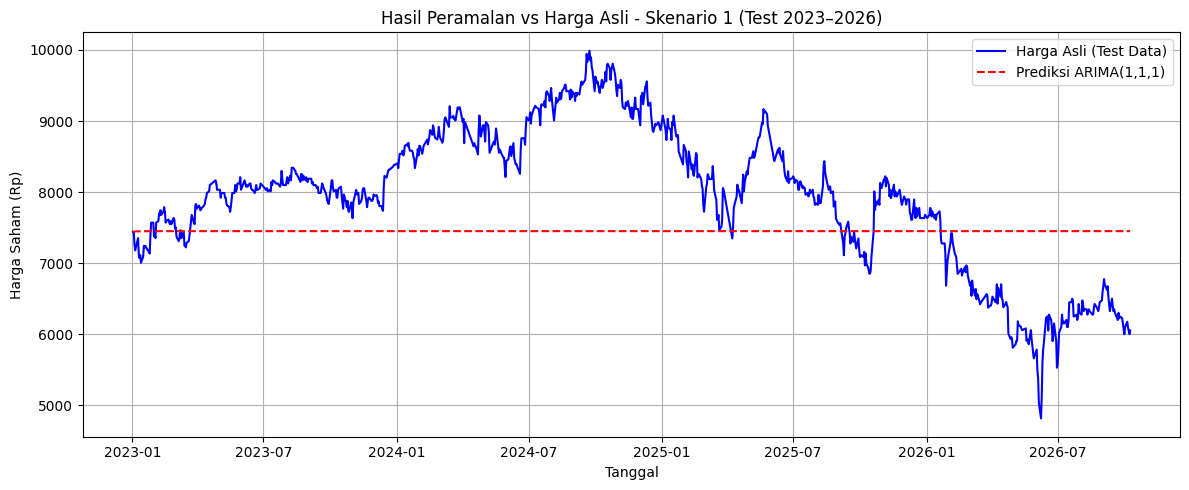

HASIL EVALUASI PERAMALAN: Skenario 2 (Test 2025–2026)
Jumlah Periode Test : 419 hari kerja
Nilai RMSE          : Rp 1829.02
Nilai MAPE          : 23.53%



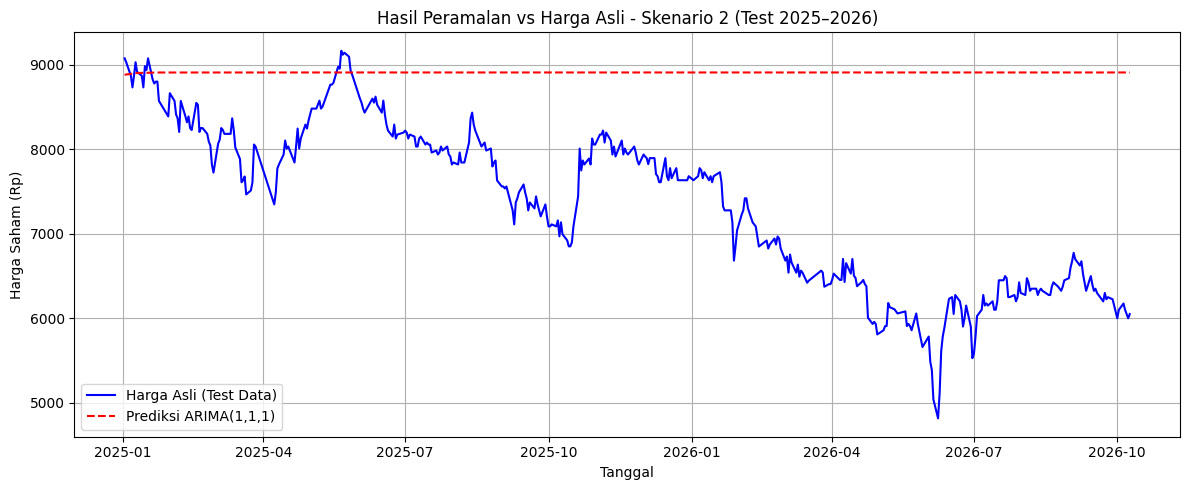

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import inv_boxcox
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
from statsmodels.tsa.arima.model import ARIMA

# Lambda optimal masing-masing skenario
lambda_sk1 = 0.1737
lambda_sk2 = 0.1708


def forecast_dan_evaluasi(train_bc, test_asli, order, lmbda, nama_skenario):
  # 1. Fit Model ARIMA(1,1,1) menggunakan .values untuk menghindari isu frekuensi tanggal bursa
  model_fit = ARIMA(train_bc.values, order=order).fit()

  # 2. Peramalan (Forecasting) Sepanjang Periode Test
  n_steps = len(test_asli)
  forecast_bc_vals = model_fit.forecast(steps=n_steps)

  # Buat pd.Series dengan indeks tanggal dari test_asli
  forecast_bc = pd.Series(forecast_bc_vals, index=test_asli.index)

  # 3. Transformasi Balik (Inverse Box-Cox) ke Skala Rupiah Asli
  forecast_asli = inv_boxcox(forecast_bc, lmbda)

  # 4. Perhitungan Metrik Evaluasi (RMSE & MAPE)
  rmse = np.sqrt(mean_squared_error(test_asli, forecast_asli))
  mape = mean_absolute_percentage_error(test_asli, forecast_asli) * 100

  print(f"==================================================")
  print(f"HASIL EVALUASI PERAMALAN: {nama_skenario}")
  print(f"==================================================")
  print(f"Jumlah Periode Test : {n_steps} hari kerja")
  print(f"Nilai RMSE          : Rp {rmse:.2f}")
  print(f"Nilai MAPE          : {mape:.2f}%")
  print(f"==================================================\n")

  # 5. Visualisasi Hasil Prediksi vs Harga Asli
  plt.figure(figsize=(12, 5))
  plt.plot(
      test_asli.index,
      test_asli,
      label="Harga Asli (Test Data)",
      color="blue",
      linewidth=1.5,
  )
  plt.plot(
      forecast_asli.index,
      forecast_asli,
      label="Prediksi ARIMA(1,1,1)",
      color="red",
      linestyle="--",
      linewidth=1.5,
  )
  plt.title(f"Hasil Peramalan vs Harga Asli - {nama_skenario}")
  plt.xlabel("Tanggal")
  plt.ylabel("Harga Saham (Rp)")
  plt.legend()
  plt.grid(True)
  plt.tight_layout()
  plt.show()

  return forecast_asli, rmse, mape


# Eksekusi Peramalan Skenario 1
fc_sk1, rmse_sk1, mape_sk1 = forecast_dan_evaluasi(
    train_sk1_bc, test_sk1, (1, 1, 1), lambda_sk1, "Skenario 1 (Test 2023–2026)"
)

# Eksekusi Peramalan Skenario 2
fc_sk2, rmse_sk2, mape_sk2 = forecast_dan_evaluasi(
    train_sk2_bc, test_sk2, (1, 1, 1), lambda_sk2, "Skenario 2 (Test 2025–2026)"
)

SKENARIO 3: Train < Sept 2026 vs Test >= Sept 2026
Jumlah Data Training : 5476 hari kerja
Jumlah Data Testing  : 31 hari kerja
Lambda Box-Cox (MLE) : 0.2183

HASIL EVALUASI PERAMALAN: Skenario 3 (Sept–Okt 2026)
Jumlah Periode Test : 31 hari kerja
Nilai RMSE          : Rp 278.47
Nilai MAPE          : 3.94%



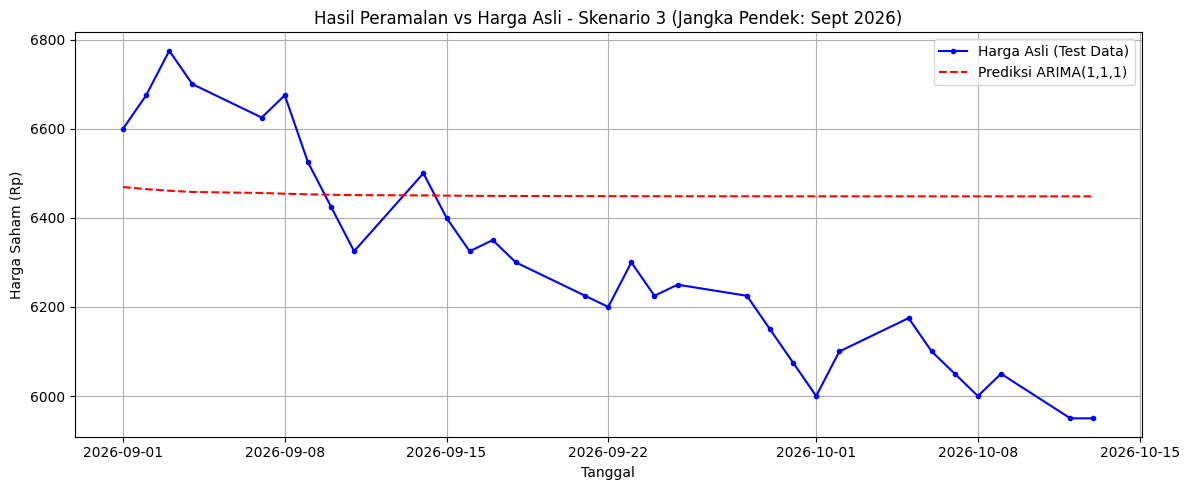

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import inv_boxcox
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
from statsmodels.tsa.arima.model import ARIMA

# 1. Split Data Skenario 3 (Cut-off 1 September 2026) menggunakan variabel 'harga'
train_sk3 = harga[harga.index < '2026-09-01']
test_sk3 = harga[harga.index >= '2026-09-01']

# 2. Estimasi Lambda Box-Cox Optimal untuk Train Skenario 3
train_sk3_bc_array, lambda_sk3 = stats.boxcox(train_sk3)
train_sk3_bc = pd.Series(train_sk3_bc_array, index=train_sk3.index)

print("==================================================")
print("SKENARIO 3: Train < Sept 2026 vs Test >= Sept 2026")
print("==================================================")
print(f"Jumlah Data Training : {len(train_sk3)} hari kerja")
print(f"Jumlah Data Testing  : {len(test_sk3)} hari kerja")
print(f"Lambda Box-Cox (MLE) : {lambda_sk3:.4f}\n")

# 3. Fit Model ARIMA(1,1,1) pada Data Box-Cox Training
model_sk3_fit = ARIMA(train_sk3_bc.values, order=(1, 1, 1)).fit()

# 4. Forecasting Sepanjang Periode Test
n_steps_sk3 = len(test_sk3)
forecast_sk3_bc_vals = model_sk3_fit.forecast(steps=n_steps_sk3)
forecast_sk3_bc = pd.Series(forecast_sk3_bc_vals, index=test_sk3.index)

# 5. Inverse Box-Cox Transform Kembali ke Skala Rupiah Asli
forecast_sk3_asli = inv_boxcox(forecast_sk3_bc, lambda_sk3)

# 6. Hitung Metrik Evaluasi (RMSE & MAPE)
rmse_sk3 = np.sqrt(mean_squared_error(test_sk3, forecast_sk3_asli))
mape_sk3 = mean_absolute_percentage_error(test_sk3, forecast_sk3_asli) * 100

print("==================================================")
print("HASIL EVALUASI PERAMALAN: Skenario 3 (Sept–Okt 2026)")
print("==================================================")
print(f"Jumlah Periode Test : {n_steps_sk3} hari kerja")
print(f"Nilai RMSE          : Rp {rmse_sk3:.2f}")
print(f"Nilai MAPE          : {mape_sk3:.2f}%")
print("==================================================\n")

# 7. Visualisasi Hasil Prediksi vs Harga Asli
plt.figure(figsize=(12, 5))
plt.plot(test_sk3.index, test_sk3, label='Harga Asli (Test Data)', color='blue', linewidth=1.5, marker='o', markersize=3)
plt.plot(forecast_sk3_asli.index, forecast_sk3_asli, label='Prediksi ARIMA(1,1,1)', color='red', linestyle='--', linewidth=1.5)
plt.title('Hasil Peramalan vs Harga Asli - Skenario 3 (Jangka Pendek: Sept 2026)')
plt.xlabel('Tanggal')
plt.ylabel('Harga Saham (Rp)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Untuk pengujian musiman (seasonality), ada 2 cara utama:
- Secara Visual: Menggunakan Monthly Boxplot (melihat sebaran IHSG per bulan untuk cek apakah bulan tertentu konsisten lebih tinggi/rendah) dan melihat lonjakan (spike) pada lag kelipatan 12 di plot ACF setelah differencing.
- Secara Formal: Menggunakan uji Seasonal Unit Root seperti OCSB Test (Osborn, Chui, Smith, and Birchenhall) atau CH Test (Canova-Hansen) untuk menentukan apakah kita butuh differencing musiman ($D$).

/tmp/ipykernel_907/1554794277.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Month', y='Log_Return', data=df_monthly, palette='Set3')


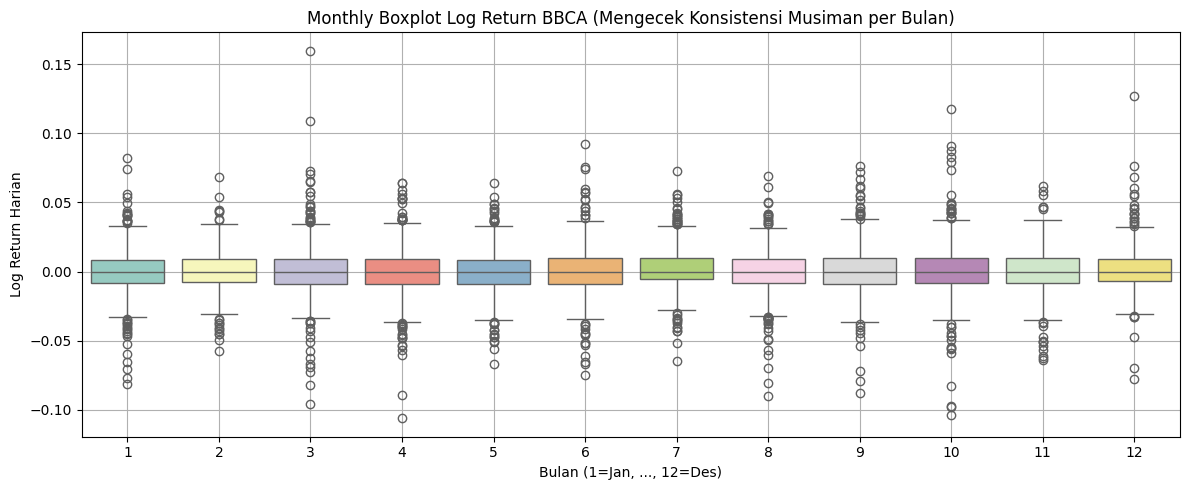

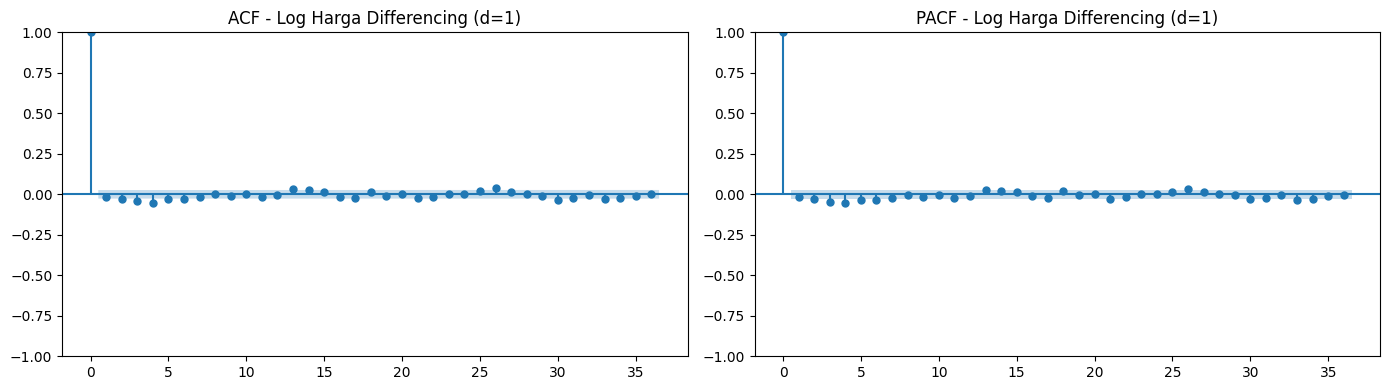

=== UJI STASIONERITAS: Log Harga Asli ===


/tmp/ipykernel_907/1554794277.py:39: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series)
/tmp/ipykernel_907/1554794277.py:45: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(series, regression='c', nlags="auto")
/tmp/ipykernel_907/1554794277.py:45: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSRes

ADF Statistic : -3.1240
p-value       : 0.0248
Kesimpulan ADF: Stasioner
KPSS Statistic: 11.9570
p-value       : 0.0100
Kesimpulan KPSS: TIDAK Stasioner

=== UJI STASIONERITAS: Log Harga Differencing (d=1) ===
ADF Statistic : -31.9032
p-value       : 0.0000
Kesimpulan ADF: Stasioner
KPSS Statistic: 0.6846
p-value       : 0.0149
Kesimpulan KPSS: TIDAK Stasioner

Library 'pmdarima' belum terinstal. Jalankan 'pip install pmdarima' untuk uji OCSB/CH.


/tmp/ipykernel_907/1554794277.py:39: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series)
/tmp/ipykernel_907/1554794277.py:45: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(series, regression='c', nlags="auto")


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

# 1. Transformasi Log dan First Differencing (d=1)
log_harga = np.log(harga_clean)
log_diff = log_harga.diff().dropna()

# 2. Visualisasi Musiman 1: Monthly Boxplot (Log Return / Log Price Change)
df_monthly = pd.DataFrame({'Log_Return': log_diff, 'Month': log_diff.index.month})

plt.figure(figsize=(12, 5))
sns.boxplot(x='Month', y='Log_Return', data=df_monthly, palette='Set3')
plt.title('Monthly Boxplot Log Return BBCA (Mengecek Konsistensi Musiman per Bulan)')
plt.xlabel('Bulan (1=Jan, ..., 12=Des)')
plt.ylabel('Log Return Harian')
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Visualisasi Musiman 2: Plot ACF & PACF setelah Differencing Pertama (d=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Cek hingga Lag 36 untuk melihat apakah ada lonjakan pada kelipatan lag 12
plot_acf(log_diff, ax=axes[0], lags=36, title="ACF - Log Harga Differencing (d=1)")
plot_pacf(log_diff, ax=axes[1], lags=36, title="PACF - Log Harga Differencing (d=1)")

plt.tight_layout()
plt.show()

# 4. Pengujian Formal Stasioneritas & Unit Root (ADF & KPSS Test)
def uji_stasioneritas(series, name="Series"):
    print(f"=== UJI STASIONERITAS: {name} ===")

    # ADF Test
    adf_result = adfuller(series)
    print(f"ADF Statistic : {adf_result[0]:.4f}")
    print(f"p-value       : {adf_result[1]:.4f}")
    print("Kesimpulan ADF: " + ("Stasioner" if adf_result[1] < 0.05 else "TIDAK Stasioner (Ada Unit Root)"))

    # KPSS Test
    kpss_result = kpss(series, regression='c', nlags="auto")
    print(f"KPSS Statistic: {kpss_result[0]:.4f}")
    print(f"p-value       : {kpss_result[1]:.4f}")
    print("Kesimpulan KPSS: " + ("TIDAK Stasioner" if kpss_result[1] < 0.05 else "Stasioner") + "\n")

uji_stasioneritas(log_harga, "Log Harga Asli")
uji_stasioneritas(log_diff, "Log Harga Differencing (d=1)")

# 5. Uji Formal Seasonal Unit Root (OCSB Test / CH Test jika pmdarima installed)
try:
    from pmdarima.arima.seasonality import OCSBTest, CHTest

    # Karena data harian, kita agregasi ke bulanan dulu untuk uji musiman tahunan m=12
    log_harga_monthly = log_harga.resample('M').last()

    ocsb = OCSBTest(m=12)
    ch = CHTest(m=12)

    print("=== UJI FORMAL MUSIMAN (DATA BULANAN, m=12) ===")
    print(f"OCSB Test estimate D (Seasonal Diff): {ocsb.estimate_seasonal_differencing_term(log_harga_monthly)}")
    print(f"CH Test estimate D (Seasonal Diff)  : {ch.estimate_seasonal_differencing_term(log_harga_monthly)}")
except ImportError:
    print("Library 'pmdarima' belum terinstal. Jalankan 'pip install pmdarima' untuk uji OCSB/CH.")